# Trabajo de final de máster de Big Data & Data Science de la Universidad de Barcelona

- Entrega: 5
- Fecha: 09/02/2022
- Autores: Mario Mérida, Jesus García Solsana, Eduerdo Farías Pedreros

---
# Identificar y localizar anomalías de COVID-19 en radiografías de tórax de la competencia de kaggle "[SIIM-FISABIO-RSNA COVID-19 Detection](https://www.kaggle.com/c/siim-covid19-detection)".

Cinco veces más letal que la gripe, el COVID-19 causa una morbilidad y mortalidad significativas. Al igual que otras neumonías, la infección pulmonar por COVID-19 produce inflamación y líquido en los pulmones. El COVID-19 se parece mucho a otras neumonías virales y bacterianas en las radiografías de tórax, lo que dificulta su diagnóstico. Su modelo de visión artificial para detectar y localizar la COVID-19 ayudaría a los médicos a proporcionar un diagnóstico rápido y fiable. Como resultado, los pacientes podrían recibir el tratamiento adecuado antes de que se produzcan los efectos más graves del virus.

Actualmente, COVID-19 se puede diagnosticar mediante la reacción en cadena de la polimerasa para detectar material genético del virus o una radiografía de tórax. Sin embargo, pueden pasar algunas horas y, a veces, días antes de que se obtengan los resultados de las pruebas moleculares. Por el contrario, las radiografías de tórax se pueden obtener en minutos. Si bien existen pautas para ayudar a los radiólogos a diferenciar el COVID-19 de otros tipos de infección, sus evaluaciones varían. Además, los no radiólogos podrían recibir apoyo con una mejor localización de la enfermedad, como con un cuadro delimitador visual.

Como organización de atención médica líder en su campo, la misión de la Society for Imaging Informatics in Medicine (SIIM) es promover la informática de imágenes médicas a través de la educación, la investigación y la innovación. SIIM se ha asociado con la Fundación para el Fomento de la Investigación Sanitaria y Biomédica de la Comunidad Valenciana (FISABIO), el Banco de Datos de Imagen Médica de la Comunidad Valenciana (BIMCV) y la Sociedad Radiológica de Norteamérica (RSNA) para este concurso.

En esta competencia, identificará y localizará anomalías de COVID-19 en radiografías de tórax. En particular, clasificará las radiografías como negativas para neumonía o típicas, indeterminadas o atípicas para COVID-19. Usted y su modelo trabajarán con datos de imágenes y anotaciones de un grupo de radiólogos.

Si tiene éxito, ayudará a los radiólogos a diagnosticar a los millones de pacientes con COVID-19 con mayor confianza y rapidez. Esto también permitirá a los médicos ver el alcance de la enfermedad y ayudarlos a tomar decisiones sobre el tratamiento. Dependiendo de la gravedad, los pacientes afectados pueden necesitar hospitalización, ingreso en una unidad de cuidados intensivos o terapias de apoyo como ventilación mecánica. Como resultado de un mejor diagnóstico, más pacientes recibirán rápidamente la mejor atención para su condición, lo que podría mitigar los efectos más severos del virus.

Esta es una competencia de código. Consulte [Requisitos del código](https://www.kaggle.com/c/siim-covid19-detection/overview/code-requirements) para obtener más información.

### Organizaciones anfitrionas

**FISABIO, Fundación para el Fomento de la Salud y la Investigación Biomédica de la Comunidad Valenciana**

La Fundación para el Fomento de la Investigación Biomédica y Sanitaria de la Comunitat Valenciana, FISABIO, es una entidad científica y asistencial sin ánimo de lucro, que tiene como finalidad principal el fomento, la promoción y el desarrollo de la investigación científico-técnica biomédica y sanitaria en la Comunitat Valenciana. FISABIO integra y gestiona el Mapa de Investigación Sanitaria del Centro de Investigación en Salud Pública, Fundación Hospital Universitario Dr. Peset, Fundación Hospital General Universitario de Alicante, Fundación Hospital General Universitario de Elche y Fundación Oftalmológica del Mediterráneo. La instalación de BIMCV está conectada con un archivo neutral de proveedores (VNA) de varios niveles. La instalación de imagen de población almacena datos de la Comunidad Valenciana, que cuenta con más de 5,1 millones de habitantes.

**Sociedad Radiológica de América del Norte (RSNA)**

La Sociedad Radiológica de América del Norte (RSNA) es una organización sin fines de lucro que representa a 31 subespecialidades radiológicas de 145 países de todo el mundo. RSNA promueve la excelencia en la atención al paciente y la prestación de atención médica a través de la educación, la investigación y la innovación tecnológica.

RSNA proporciona recursos educativos de alta calidad, publica cinco de las principales revistas revisadas por pares, organiza la conferencia de radiología más grande del mundo y se dedica a construir el futuro de la profesión a través de la Fundación RSNA Research & Education (R&E), que ha financiado $66 millones en subvenciones. desde su concepción. RSNA también apoya y facilita la investigación de inteligencia artificial (IA) en imágenes médicas mediante el patrocinio de una serie continua de concursos de desafíos de IA.

---
# Carga de librerias

In [1]:
# para tratamiento de datos
import numpy as np
import pandas as pd
import json
import os, shutil
import sys

# ejecutamos desde la raiz del repositorio para que las rutas relativas funcionen
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import csv
import pickle


# para procesamiento de imagenes
import pydicom as dicom
import cv2
from PIL import Image
from skimage.metrics import structural_similarity as ssim
import re
import imageio
# compatibilidad de imgaug 0.4 con NumPy 2 (np.sctypes fue eliminado)
if not hasattr(np, 'sctypes'):
    np.sctypes = {'int': [np.int8, np.int16, np.int32, np.int64],
                  'uint': [np.uint8, np.uint16, np.uint32, np.uint64],
                  'float': [np.float16, np.float32, np.float64],
                  'complex': [np.complex64, np.complex128],
                  'others': [bool, object, bytes, str, np.void]}
from imgaug import augmenters as iaa 
from imgaug.augmentables.bbs import BoundingBox, BoundingBoxesOnImage


# para gráficos
import matplotlib.pylab as plt

# para modelado
from tensorflow.keras import regularizers, optimizers
from sklearn import preprocessing, model_selection
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator, img_to_array
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense, BatchNormalization, Conv2D, MaxPooling2D  # para layers de modelo

# utilidades de YOLOv5 (clon local en experiments/model_3_yolov5/yolov5)
sys.path.insert(0, './experiments/model_3_yolov5/yolov5')
from utils import plots

import tensorflow as tf
import torch
import yaml
import datetime

In [61]:
# setteo de matplotlib backend
%matplotlib inline

In [62]:
#import wandb

# comenzamos carga de weights and bias 
#run = wandb.init()

# finalizamos carga de weights and bias 
#run.finish()

---
# Análisis exploratorio


## Análisis de imágenes

### Exploración de imagen `dicom`

In [63]:
def show_dcm_file(return_file_meta,dir):
    
    """Función para ver imágen DCM y sus principales características.
    - return_file_meta: opción para que la función regrese la imagen y almacenarla en una variable.
    - dir: directorio de imagen/imágenes DCM a mostrar.""" 
    
    # lista auxiliar
    dcm_file_name = []
    dcm_list = []
    dcm_list_full_dir = []
    
    # obtenemos nombre de archivos y ruta
    for root, directories, files in os.walk(dir, topdown=False):
        for name in files:
            dcm_dir = os.path.join(root)
            dcm_file_name = os.path.join(name)

            # ruta completa a imagen DCM a mostrar
            dcm_full_dir = os.path.join(dcm_dir, dcm_file_name)

            # cargamos la imagen
            dcm = dicom.dcmread(dcm_full_dir)

            # muestra de resultados
            if return_file_meta == True:
                dcm_list_full_dir.append(dcm_full_dir)
                dcm_list.append(dicom.dcmread(dcm_full_dir))
            else:
                print('Ruta de imagen/imágenes:', dcm_dir)
                print('ID estudio:', dcm_file_name)
                print("Tipo de imagen:", type(dcm))
                print("Dimensiones de matrix de imagen:", img_to_array(dcm.pixel_array).shape)
                print('Sexo del paciente:', dcm[0x0010, 0x0040][:])
                plt.figure(figsize=(16,8))
                plt.imshow(dcm.pixel_array)
                plt.show()
                print('---------------------------------------------------------------')
                
    if not dcm_list == []:
        return dcm_list_full_dir, dcm_list

Ruta de imagen/imágenes: ./data/train/00f9e183938e/081e92373dc6
ID estudio: 6534a837497d.dcm
Tipo de imagen: <class 'pydicom.dataset.FileDataset'>
Dimensiones de matrix de imagen: (2544, 3056, 1)
Sexo del paciente: F


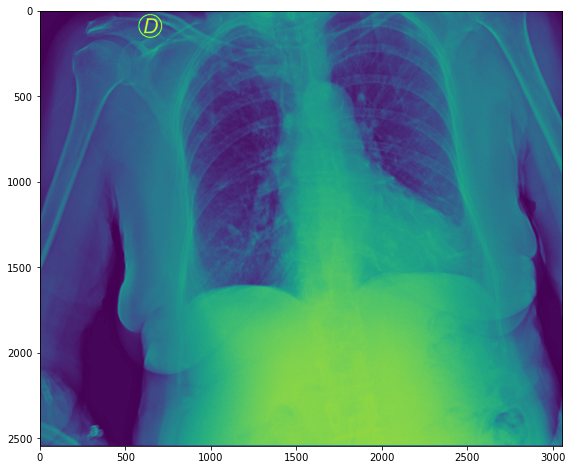

---------------------------------------------------------------
Ruta de imagen/imágenes: ./data/train/00f9e183938e/89bad86310f9
ID estudio: 74077a8e3b7c.dcm
Tipo de imagen: <class 'pydicom.dataset.FileDataset'>
Dimensiones de matrix de imagen: (2544, 3056, 1)
Sexo del paciente: F


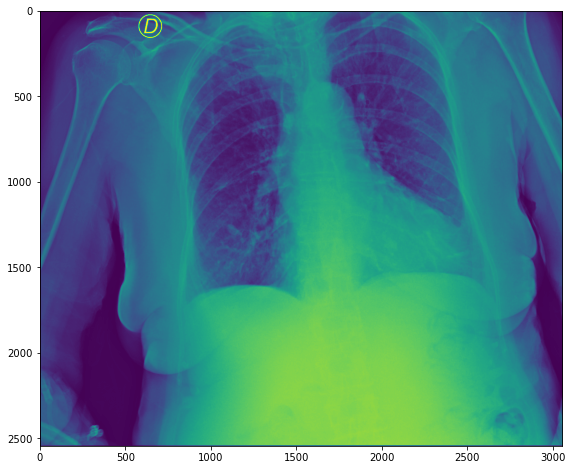

---------------------------------------------------------------


In [64]:
# mostramos imagen/imágenes DCM
show_dcm_file(return_file_meta=False,
                dir = './data/train/00f9e183938e/')

In [65]:
# ejemplo para obtener un metadato específico de imagen DCM
show_dcm_file(return_file_meta=True,
                dir = './data/train/00f9e183938e/')[1][0][0x7fe0, 0x0010]

(7fe0, 0010) Pixel Data                          OW: Array of 15548928 elements

### Conversion de `dcm` a `jpg`

In [66]:
def conv_dcm_to_jpg(input_dir,
                    output_dir = './data/examples/train_jpg/',
                    return_jpg = True):

    """Función para ver convertir archivos DCM de un directorio (inc. subdirectorios) a JPG.
    - input_dir: directorio de archivos DCM a covertir.
    - output_dir: directorio de archivos JPG.
    - return_jpg: opción para que la función regrese la imagen y almacenarla en una variable.""" 
    
    # lista de archivos DCM en el directorio input
    dcm_list = show_dcm_file(return_file_meta = True,
                                    dir = input_dir)[1]
    
    for dcm in dcm_list:
        # matriz de pixeles de imagen DCM
        dcm_pixel_array_numpy = dcm.pixel_array
        
        # normalizado de escala de imagen (de int16 a uint8)
        scaled_img = cv2.convertScaleAbs(dcm_pixel_array_numpy-np.min(dcm_pixel_array_numpy), alpha=(255.0 / min(np.max(dcm_pixel_array_numpy)-np.min(dcm_pixel_array_numpy), 10000)))

        # definimos ubicacion de archivo JPG y creamos carpeta si no existe
        if not os.path.exists(output_dir):
            os.makedirs(output_dir)

        # remplazo extenision DCM a JPG
        jpg_file_name = dcm[0x0008, 0x0018][:]+'.jpg'

        # direccion completa a imagen JPG a convertir
        jpg_full_dir = os.path.join(output_dir, jpg_file_name)

        # creamos archivo JPG en directorio dado
        result = cv2.imwrite(jpg_full_dir, scaled_img)

        # mostramos resultados    
        if result == True:
            jpg = load_img(jpg_full_dir)
            if return_jpg == True:    
                print('Imagen convertida correctamente.')
                print('Ruta de imagen/imágenes DCM:', input_dir)
                print('Ruta de imagen/imágenes JPG:', output_dir)
                print('ID estudio:', jpg_file_name)
                print("Tipo de imagen:", type(jpg))
                print("Modo de imagen:", jpg.mode)
                print("Tamaño de imagen:", jpg.size)
                print("Dimensiones de matrix de imagen:", img_to_array(jpg).shape)
                plt.figure(figsize=(16,8))
                plt.imshow(jpg)
                plt.show()
                print('---------------------------------------------------------------')
        else:
            print('Error in saving file')

Imagen convertida correctamente.
Ruta de imagen/imágenes DCM: ./data/train/00f9e183938e/
Ruta de imagen/imágenes JPG: ./data/examples/train_jpg/
ID estudio: 6534a837497d.jpg
Tipo de imagen: <class 'PIL.Image.Image'>
Modo de imagen: RGB
Tamaño de imagen: (3056, 2544)
Dimensiones de matrix de imagen: (2544, 3056, 3)


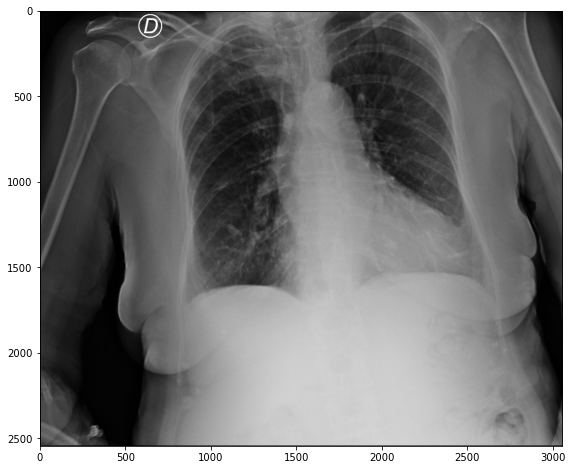

---------------------------------------------------------------
Imagen convertida correctamente.
Ruta de imagen/imágenes DCM: ./data/train/00f9e183938e/
Ruta de imagen/imágenes JPG: ./data/examples/train_jpg/
ID estudio: 74077a8e3b7c.jpg
Tipo de imagen: <class 'PIL.Image.Image'>
Modo de imagen: RGB
Tamaño de imagen: (3056, 2544)
Dimensiones de matrix de imagen: (2544, 3056, 3)


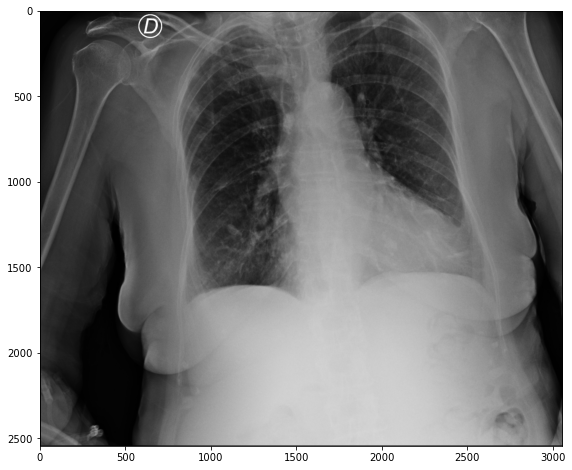

---------------------------------------------------------------


In [67]:
# conversión de imagen/imágenes DCM a JPG
conv_dcm_to_jpg(input_dir = './data/train/00f9e183938e/',
                output_dir = './data/examples/train_jpg/',
                return_jpg=True)

In [68]:
# conversión de imagen/imágenes DCM a JPG
conv_dcm_to_jpg(input_dir = './data/train/00086460a852/',
                output_dir = './data/examples/train_jpg/',
                return_jpg=False)

### Transformación de imagen `jpg` a escala de grises y tamaño reducido

In [69]:
def reduce_jpg(dir,
                jpg_file_name,
                output_basewidth = 450,
                output_subfix = '_red',
                return_jpg_red = True):
    
    """Función para ver reducir tamaño de imagen JPG y convertir a escala de grises.
    - dir: directorio de imagen original a reducir.
    - jpg_file_name: nombre de archivo JPG original a reducir.
    - output_basewidth: ancho de la imagen reducida en pixeles.
    - output_subfix: subfijo para identificar jpg reducido.
    - return_jpg_red: retorna imagen reducida.""" 

    # definimos la ruta completa de imagen original
    jpg_full_dir = dir+jpg_file_name

    #abrimos la imagen oringial y la pasamos a escala de grises
    jpg = Image.open(jpg_full_dir).convert('RGB')    
    jpg_red = Image.open(jpg_full_dir).convert('L')

    # calculamos relacion entre imagen original y nueva imagen
    wpercent = (output_basewidth / float(jpg.size[0]))

    #ajustamos el alto de la imagen
    hsize = int((float(jpg.size[1]) * float(wpercent)))

    # cambiamos el tamaño de la imagen en base al ancho dado y alto calculado
    jpg_red = jpg_red.resize((output_basewidth, hsize), Image.LANCZOS)

    # agergamos subfijo para identificar reduccion de calidad
    jpg_red_full_dir = jpg_full_dir.replace('.jpg', output_subfix+'.jpg')

    # guardamos la imagen
    jpg_red.save(jpg_red_full_dir)

    # mostramos resultados
    print('Imagen reducida correctamente.')
    if return_jpg_red == True:  
        print('Ruta de imagen/imágenes original:', jpg_full_dir)
        print('Ruta de imagen/imágenes reducida:', jpg_red_full_dir)
        print('ID estudio original:', jpg_file_name)
        print("Tipo de imagen original:", type(jpg))
        print("Tipo de imagen reducida:", type(jpg_red))
        print("Modo de imagen original:", jpg.mode)
        print("Modo de imagen reducida:", jpg_red.mode)
        print("Tamaño de imagen original:", jpg.size)
        print("Tamaño de imagen reducida:", jpg_red.size)
        print("Dimensiones de matrix de imagen original:", img_to_array(jpg).shape)
        print("Dimensiones de matrix de imagen reducida:", img_to_array(jpg_red).shape)
        plt.figure(figsize=(16,8))
        plt.imshow(jpg_red, cmap='gray')
        plt.show()
        print('---------------------------------------------------------------')

Imagen reducida correctamente.
Ruta de imagen/imágenes original: ./data/examples/train_jpg/6534a837497d.jpg
Ruta de imagen/imágenes reducida: ./data/examples/train_jpg/6534a837497d_red.jpg
ID estudio original: 6534a837497d.jpg
Tipo de imagen original: <class 'PIL.Image.Image'>
Tipo de imagen reducida: <class 'PIL.Image.Image'>
Modo de imagen original: RGB
Modo de imagen reducida: L
Tamaño de imagen original: (3056, 2544)
Tamaño de imagen reducida: (450, 374)
Dimensiones de matrix de imagen original: (2544, 3056, 3)
Dimensiones de matrix de imagen reducida: (374, 450, 1)


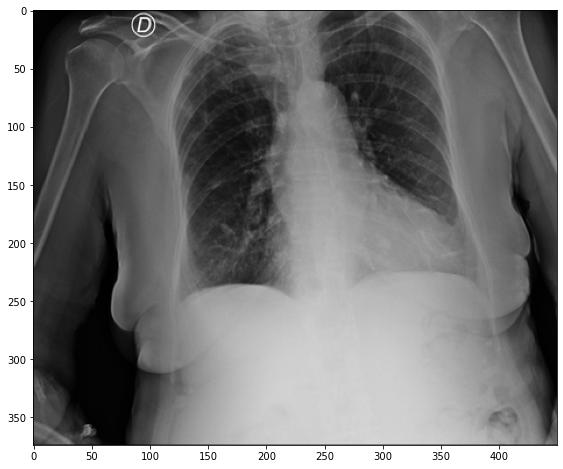

---------------------------------------------------------------


In [70]:
# reducimos una imagen JPG y pasamos a escala de grises
reduce_jpg(dir = './data/examples/train_jpg/',
                jpg_file_name = '6534a837497d.jpg',
                output_basewidth = 450,
                output_subfix = '_red',
                return_jpg_red = True)

In [71]:
# reducimos una imagen JPG y pasamos a escala de grises
reduce_jpg(dir = './data/examples/train_jpg/',
                jpg_file_name = '65761e66de9f.jpg',
                output_basewidth = 450,
                output_subfix = '_red',
                return_jpg_red = False)

Imagen reducida correctamente.


In [72]:
# reducimos una imagen JPG y pasamos a escala de grises
reduce_jpg(dir = './data/examples/train_jpg/',
                jpg_file_name = '74077a8e3b7c.jpg',
                output_basewidth = 450,
                output_subfix = '_red',
                return_jpg_red = False)

Imagen reducida correctamente.


### Conclusion

Respecto al análisis de imágenes, se concluye que por medio de la librería pydicom, las imágenes pueden leerse directamente como fueron obtenidas de la fuente en formato dcm en Python. Sin embargo, la resolución de las imágenes y la gama de colores pueden tener un coste computacional considerable al momento de analizar grandes volúmenes de datos. Se decide entonces convertir el formato de la imagen a un formato más simple de interpretar, como por ejemplo en jpg, donde se observa que la gama de colores se reduce naturalmente a escala de grises. Esto tiene sentido ya que las radiografías suelen estar en una gama de colores entre azul y negro. También analizamos la posibilidad de escalar la imagen para reducir el coste computacional a expensas de la precisión de un modelo.

---
## Análisis de dataframes

### Dataframe `train_study_level.csv`

In [73]:
# directorio de datos de entrenamiento
train_dir = "./data/train/"

# cargamos datos de estudio
df_study = pd.read_csv('./data/kaggle/train_study_level.csv')

# limpiamos datos a relacionar
df_study['study_dir'] = df_study['id'].str.replace('_study','')

# quitamos columnas redundantes
df_study = df_study.drop(columns = ['id'])

# muestra resultados
df_study[:5]

,Negative for Pneumonia,Typical Appearance,Indeterminate Appearance,Atypical Appearance,study_dir
0,0,1,0,0,00086460a852
1,0,0,0,1,000c9c05fd14
2,1,0,0,0,00292f8c37bd
3,1,0,0,0,005057b3f880
4,0,0,0,1,0051d9b12e72


### Dataframe `train_image_level.csv`

In [74]:
# cargamos datos de imagenes
df_image = pd.read_csv('./data/kaggle/train_image_level.csv')

#limpiamos los datos
df_image["image_name"] = df_image["id"].str.replace('_image', '')

#quitamos datos redundantes
df_image = df_image.drop(columns = {'id'})

# muestra resultados
df_image[:5]

,boxes,label,StudyInstanceUID,image_name
0,"[{'x': 789.28836, 'y': 582.43035, 'width': 102...",opacity 1 789.28836 582.43035 1815.94498 2499....,5776db0cec75,000a312787f2
1,NaN,none 1 0 0 1 1,ff0879eb20ed,000c3a3f293f
2,"[{'x': 677.42216, 'y': 197.97662, 'width': 867...",opacity 1 677.42216 197.97662 1545.21983 1197....,9d514ce429a7,0012ff7358bc
3,"[{'x': 2729, 'y': 2181.33331, 'width': 948.000...",opacity 1 2729 2181.33331 3677.00012 2785.33331,28dddc8559b2,001398f4ff4f
4,"[{'x': 623.23328, 'y': 1050, 'width': 714, 'he...",opacity 1 623.23328 1050 1337.23328 2156 opaci...,dfd9fdd85a3e,001bd15d1891


### Dataframe de contentido en `carpeta train`

In [75]:
# creacion de lista auxiliar
train_walk_list = []

# carga de datos de carpetas, subcarpetas y archivos de un dado directorio
for root, directories, files in os.walk(train_dir, topdown=False):
	for name in files:
		train_walk_list.append(os.path.join(root, name))

# creacion de un dataframe con los datos obtenidos
df = pd.DataFrame(train_walk_list)

# separacion de datos en columnas
df[0] = df[0].str.replace('\\', '/', regex=False)
df[['data','root','train_dir', 'study_dir','study_subdir', 'image_name']] = df[0].str.split('/', expand=True)
df[['image_name', 'ext']] = df['image_name'].str.split('.',expand=True)
df['full_dir'] = df[0]

# quitamos columnas redundantes
df = df.drop(columns = [0, 'data', 'root', 'train_dir', 'ext'])

# mostrar resultados
df[:5]

,study_dir,study_subdir,image_name,full_dir
0,00086460a852,9e8302230c91,65761e66de9f,./data/train/00086460a852/9e8302230c91/65761e6...
1,000c9c05fd14,e555410bd2cd,51759b5579bc,./data/train/000c9c05fd14/e555410bd2cd/51759b5...
2,00292f8c37bd,73120b4a13cb,f6293b1c49e2,./data/train/00292f8c37bd/73120b4a13cb/f6293b1...
3,005057b3f880,e34afce999c5,3019399c31f4,./data/train/005057b3f880/e34afce999c5/3019399...
4,0051d9b12e72,152f6ec68d86,bb4b1da810f3,./data/train/0051d9b12e72/152f6ec68d86/bb4b1da...


### Union de dataframe de `carpeta train` con `train_study_level.csv` y `train_image_level.csv`.

In [76]:
# union con train_study
df = df.merge(right = df_study, how = 'left')

# union con train_image
df = df.merge(right = df_image, how = 'left')

# muestra de resultados
df[:5]

,study_dir,study_subdir,image_name,full_dir,Negative for Pneumonia,...,Indeterminate Appearance,Atypical Appearance,boxes,label,StudyInstanceUID
0,00086460a852,9e8302230c91,65761e66de9f,./data/train/00086460a852/9e8302230c91/65761e6...,0,...,0,0,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852
1,000c9c05fd14,e555410bd2cd,51759b5579bc,./data/train/000c9c05fd14/e555410bd2cd/51759b5...,0,...,0,1,NaN,none 1 0 0 1 1,000c9c05fd14
2,00292f8c37bd,73120b4a13cb,f6293b1c49e2,./data/train/00292f8c37bd/73120b4a13cb/f6293b1...,1,...,0,0,NaN,none 1 0 0 1 1,00292f8c37bd
3,005057b3f880,e34afce999c5,3019399c31f4,./data/train/005057b3f880/e34afce999c5/3019399...,1,...,0,0,NaN,none 1 0 0 1 1,005057b3f880
4,0051d9b12e72,152f6ec68d86,bb4b1da810f3,./data/train/0051d9b12e72/152f6ec68d86/bb4b1da...,0,...,0,1,"[{'x': 812.54698, 'y': 1376.41291, 'width': 62...",opacity 1 812.54698 1376.41291 1435.14793 1806...,0051d9b12e72


### Clases de diagnostico

In [77]:
# creamos función de clasificación
def label_diag(row):
   
   """Funcion para clasificar las columnas de diagnóstico en una sóla columna (datos de formato wide a long)."""
   
   if row['Negative for Pneumonia'] == 1 :
      return 'neg_for_pneumonia'
   if row['Typical Appearance'] == 1 :
      return 'typical'
   if row['Indeterminate Appearance'] == 1 :
      return 'indeterminate'
   if row['Atypical Appearance'] == 1 :
      return 'atypical'
   return 'Other'

In [78]:
# pasamos datos wide a long
df['diagnostic_cat'] = df.apply (lambda row: label_diag(row), axis=1)

#quitamos datos redundantes
df = df.drop(columns=['study_subdir', 'Negative for Pneumonia', 'Typical Appearance', 'Indeterminate Appearance', 'Atypical Appearance'])

# mostramos resultados
df[:5]

,study_dir,image_name,full_dir,boxes,label,StudyInstanceUID,diagnostic_cat
0,00086460a852,65761e66de9f,./data/train/00086460a852/9e8302230c91/65761e6...,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852,typical
1,000c9c05fd14,51759b5579bc,./data/train/000c9c05fd14/e555410bd2cd/51759b5...,NaN,none 1 0 0 1 1,000c9c05fd14,atypical
2,00292f8c37bd,f6293b1c49e2,./data/train/00292f8c37bd/73120b4a13cb/f6293b1...,NaN,none 1 0 0 1 1,00292f8c37bd,neg_for_pneumonia
3,005057b3f880,3019399c31f4,./data/train/005057b3f880/e34afce999c5/3019399...,NaN,none 1 0 0 1 1,005057b3f880,neg_for_pneumonia
4,0051d9b12e72,bb4b1da810f3,./data/train/0051d9b12e72/152f6ec68d86/bb4b1da...,"[{'x': 812.54698, 'y': 1376.41291, 'width': 62...",opacity 1 812.54698 1376.41291 1435.14793 1806...,0051d9b12e72,atypical


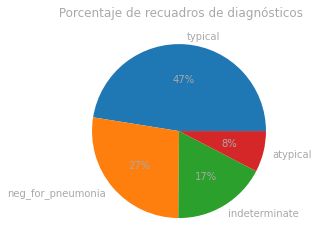

In [79]:
# parámetros de gráfico
plt.rcParams['text.color'] = 'darkgrey'
plt.axis('off')

# frecuencias absolutas de diagnósticos
ax = (df[['diagnostic_cat']].value_counts(normalize=True).round(4) * 100).plot(kind='pie', 
                                                                                autopct='%1.0f%%',
                                                                                labels = (df['diagnostic_cat'].value_counts(normalize=True).round(4) * 100).index.tolist(),
                                                                                title=' Porcentaje de recuadros de diagnósticos',
                                                                                )

plt.show()

In [80]:
# resumen información del fichero
df.drop(columns=['full_dir']).describe(include='all')

,study_dir,image_name,boxes,label,StudyInstanceUID,diagnostic_cat
count,6334,6334,4294,6334,6334,6334
unique,6054,6334,4294,4295,6054,4
top,0fd2db233deb,65761e66de9f,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",none 1 0 0 1 1,0fd2db233deb,typical
freq,9,1,1,2040,9,3007


### Conclusion

Respecto al análisis de dataframes, al comparar los datos dados en los csv con los archivos dados (radiografías) y subcarpetas dentro de la carpeta train se observa que hay carpetas study_dir que se repiten. Es decir que hay pacientes que tienen más de una radiografía. Los estudios tienen todos nombres distintos, pero quizás existan datos duplicados o en blanco. Esto aparentemente sólo se podría corroborar visualizando la imagen. La cantidad de datos están distribuidos de la forma esperada no equitativa que es: mayor cantidad de radiografías con diagnóstico típico, luego casos negativos para neumonía, en tercer lugar casos indeterminados y finalmente, en menor proporción, casos atípicos.

---
## Análisis simultaneo de imágenes y dataframes

### Parseo de `boxes`(lista de diccionarios) y `labels`(str) a `dataframe`

In [81]:
# creamos función para agregar extensión a nombre de archivo
def append_ext(fn):
    
    """Función para agregar extension JPG a los valores en una columna de un dataframe."""
    
    return fn+".jpg"

In [82]:
# agregamos extension en image_name
df["image_name_jpg"]=df['image_name'].apply(append_ext)

#quitamos datos redundantes
df = df.drop(columns=['image_name'])

# mostramos resultados
df[:5]

,study_dir,full_dir,boxes,label,StudyInstanceUID,diagnostic_cat,image_name_jpg
0,00086460a852,./data/train/00086460a852/9e8302230c91/65761e6...,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852,typical,65761e66de9f.jpg
1,000c9c05fd14,./data/train/000c9c05fd14/e555410bd2cd/51759b5...,NaN,none 1 0 0 1 1,000c9c05fd14,atypical,51759b5579bc.jpg
2,00292f8c37bd,./data/train/00292f8c37bd/73120b4a13cb/f6293b1...,NaN,none 1 0 0 1 1,00292f8c37bd,neg_for_pneumonia,f6293b1c49e2.jpg
3,005057b3f880,./data/train/005057b3f880/e34afce999c5/3019399...,NaN,none 1 0 0 1 1,005057b3f880,neg_for_pneumonia,3019399c31f4.jpg
4,0051d9b12e72,./data/train/0051d9b12e72/152f6ec68d86/bb4b1da...,"[{'x': 812.54698, 'y': 1376.41291, 'width': 62...",opacity 1 812.54698 1376.41291 1435.14793 1806...,0051d9b12e72,atypical,bb4b1da810f3.jpg


In [83]:
df_boxes = pd.DataFrame(df.loc[df['image_name_jpg'] == '65761e66de9f.jpg', 'boxes':'diagnostic_cat'].copy())

df_boxes

,boxes,label,StudyInstanceUID,diagnostic_cat
0,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852,typical


In [84]:
df_boxes

,boxes,label,StudyInstanceUID,diagnostic_cat
0,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852,typical


In [85]:
def vis_diag_box(jpg_file):
    
    """Función para parsear y visualizar diagnósticos de un estudio en un dataframe.

    Args:
        jpg_file: es el ID del estudio con extensión en JPG.

    Returns:
        dataframe: dataframe de boxes con diagnósticos.
    """
    
    # copiamos los datos del estudio a un dataframe
    df_boxes = pd.DataFrame(df.loc[df['image_name_jpg'] == jpg_file, 'boxes':'diagnostic_cat'].copy())
    
    # parseo de datos str a diccionario
    if "none" in str(df_boxes['label']):
        df_boxes['image_name_jpg'] = jpg_file
        df_boxes = df_boxes.reset_index(drop = True)
        df_boxes['box'] = pd.NA
        df_boxes['label_diagnostic'] = 'none'
        df_boxes['label_diagnostic_prob'] = 1
        df_boxes.drop(columns = ['boxes', 'label', 'StudyInstanceUID', 'diagnostic_cat'], inplace = True)
        return df_boxes
    else:
        df_boxes['boxes'] = df_boxes['boxes'].apply(eval)
        # transformacion de las listas a filas en el dataframe
        df_boxes = df_boxes.explode('boxes').reset_index(drop = True)
        # creamos columnas para almacenar datos
        df_boxes['image_name_jpg'] = jpg_file
        df_boxes['box'] = None
        df_boxes['x'] = None
        df_boxes['y'] = None
        df_boxes['width'] = None
        df_boxes['height'] = None
        df_boxes['label_diagnostic'] = None
        df_boxes['label_diagnostic_prob'] = None
        # copiamos datos de estudio a nuevas columnas
        for i in range(len(df_boxes)):
            df_boxes.loc[i, 'box'] = i
            df_boxes.loc[i, 'x'] = df_boxes.loc[i, 'boxes']['x']
            df_boxes.loc[i, 'y'] = df_boxes.loc[i, 'boxes']['y']
            df_boxes.loc[i, 'width'] = df_boxes.loc[i, 'boxes']['width']
            df_boxes.loc[i, 'height'] = df_boxes.loc[i, 'boxes']['height']
            df_boxes.loc[i, 'label_diagnostic'] = df_boxes.loc[i, 'diagnostic_cat']
            df_boxes.loc[i, 'label_diagnostic_prob'] = pd.Series(df_boxes.loc[0, 'label']).str.split(' ', n=0, expand=True).loc()[0,i+1+5*i]
        # quitamos columnas no necesarias
        df_boxes.drop(columns = ['boxes', 'label', 'StudyInstanceUID', 'diagnostic_cat'], inplace = True)
        # transformamos las columnas a numerico
        for column in df_boxes:
            if column != 'image_name_jpg' and column != 'label_diagnostic': 
                df_boxes[column] = df_boxes[column].astype(float)
        # muestra resultados
        return df_boxes

In [86]:
# mostramos diagnósticos por recuadro de un estudio específico
vis_diag_box(jpg_file = '65761e66de9f.jpg')

,image_name_jpg,box,x,y,width,height,label_diagnostic,label_diagnostic_prob
0,65761e66de9f.jpg,0.0,720.65215,636.51048,332.19348,648.12561,typical,1.0
1,65761e66de9f.jpg,1.0,2044.77989,847.90622,329.87049,576.11169,typical,1.0


In [87]:
# mostramos diagnósticos por recuadro de un estudio específico
vis_diag_box(jpg_file = '6534a837497d.jpg')

,image_name_jpg,box,label_diagnostic,label_diagnostic_prob
0,6534a837497d.jpg,<NA>,none,1


In [88]:
# mostramos diagnósticos por recuadro de un estudio específico
vis_diag_box(jpg_file = '74077a8e3b7c.jpg')

,image_name_jpg,box,x,y,width,height,label_diagnostic,label_diagnostic_prob
0,74077a8e3b7c.jpg,0.0,2175.24285,1123.72368,432.26318,500.11853,atypical,1.0
1,74077a8e3b7c.jpg,1.0,823.16390,1324.77631,306.60522,394.56580,atypical,1.0
2,74077a8e3b7c.jpg,2.0,845.78232,291.86842,201.05261,437.28949,atypical,1.0


### Abrir imagen `jpg` en escala de grises y reducida con diagnostico en recuadro

In [89]:
# creamos función para abrir/ver imágenes JPG
def open_jpgs(jpg_file_name,
                red_jpg_file_name,
                dir = './data/examples/train_jpg/'):
    
    """Función para abrir 2 rutas e imágenes JPGs (original y reducida respectivamente).
    - jpg_file_name: nombre de imagen de estudio original.
    - red_jpg_file_name: nombre de imagen de estudio reducida.
    - dir: directorio con ubicación de archivos JPG original y reducio a abrir."""

    # definimos la ruta completa de imágen original y reducida
    jpg_full_dir = dir+jpg_file_name    
    red_jpg_full_dir = dir+red_jpg_file_name

    #abrimos la imagen oringial y la pasamos a escala de grises
    jpg = Image.open(jpg_full_dir).convert('RGB')   
    jpg_red = Image.open(red_jpg_full_dir).convert('L')

    return jpg_full_dir, jpg, red_jpg_full_dir, jpg_red


In [90]:
# creamos función para ver dataframes con datos de recuadros de diagnósticos
def vis_diag_jpg(file_name,
                    scale,
                    red_subfix = '_red',
                    dir = './data/examples/train_jpg/'):
    
    """Función para visualizar imagen con recuadros con diagnóstico en imágen JPG reducida.
    - file_name: nombre de archivo JPG al que se le agregarán los recuadros con diagnósticos.
    - scale: porcentaje de escalado entre imagen reducida sobre imagen original.
    - dir: directorio donde se encuentra el archivo JPG.""" 
    
    # verificamos nombre de archivo JPG original o reducido
    if red_subfix not in file_name:
        original = True
        jpg_file_name = file_name
        red_jpg_file_name = file_name.replace('.jpg', red_subfix+'.jpg')
    
    else:
        original = False
        jpg_file_name = file_name.replace(red_subfix,'')
        red_jpg_file_name = file_name
        
    # creación ded dataframe de boxes
    df_boxes = vis_diag_box(jpg_file_name)
    
    if df_boxes['label_diagnostic'][0] == 'none':
        print('Ruta de imagen:', dir)
        print('ID estudio:', file_name)
        print('Este estudio no tiene recuadros de diagnóstico.')
        plt.figure(figsize=(16,8))
        plt.imshow(Image.open(dir+file_name).convert('L'), cmap='gray')
        plt.show()
        print('---------------------------------------------------------------')
        return
    else:
        
        # bucle para cargar todos los recuadros    
        for box in range(len(df_boxes)):

            if original == True:
                # cargamos la imagen original
                img = cv2.imread(dir+jpg_file_name)
                scale = 1
                thickness = 3

            else:
                # cargamos la imagen REDUCIDA
                img = cv2.imread(dir+red_jpg_file_name)
                thickness = 1
            
            # cargamos las coordenadas de la esquina SUPERIOR IZQUIERDA del recuadro
            x1 = int(df_boxes.loc[df_boxes["image_name_jpg"] == jpg_file_name, 'x'][box] * scale)
            y1 = int(df_boxes.loc[df_boxes["image_name_jpg"] == jpg_file_name, 'y'][box] * scale)
            
            # cargamos dimensiones del recuadro
            w = int((df_boxes.loc[df_boxes["image_name_jpg"] == jpg_file_name, 'width'][box]) * scale)
            h = int((df_boxes.loc[df_boxes["image_name_jpg"] == jpg_file_name, 'height'][box]) * scale)
            
            # dibujamos un rectangulo
            img = cv2.rectangle(img = img, pt1 = (x1, y1), pt2 = (x1+w, y1+h), color = (0, 0, 255), thickness = thickness)
            print(f"Box {box}: x, y, w, h: {x1}, {y1}, {w}, {h}")
            
            # texto a incluir
            font                   = cv2.FONT_HERSHEY_SIMPLEX
            fontColor              = (0,0,255)
            if original == True:
                bottomLeftCornerOfText = (x1,y1-50)
                fontScale              = 3
                lineType               = 3
            else:
                bottomLeftCornerOfText = (x1,y1-10)
                fontScale              = 0.6
                lineType               = 1
            img_text = df_boxes.loc[df_boxes["image_name_jpg"] == jpg_file_name, 'label_diagnostic'][box]
            cv2.putText(img, img_text, bottomLeftCornerOfText, font, fontScale, fontColor, lineType)

            # guardamos la imagen
            if original == True:
                img_dir = dir+jpg_file_name
            else:
                img_dir = dir+red_jpg_file_name
        
            # guardamos la imagen
            cv2.imwrite(img_dir, img)
        
        # mostramos la imagen jpg
        print('Tamaño de imagen:', img.shape)
        if original == True:
            print("JPG original modificado.")
        else:
            print("JPG reducido modificado.")
        print('Ruta de imagen:', dir)
        print('ID estudio:', file_name)
        return load_img(dir+file_name)

Ruta de imagen: ./data/examples/train_jpg/
ID estudio: 6534a837497d_red.jpg
Este estudio no tiene recuadros de diagnóstico.


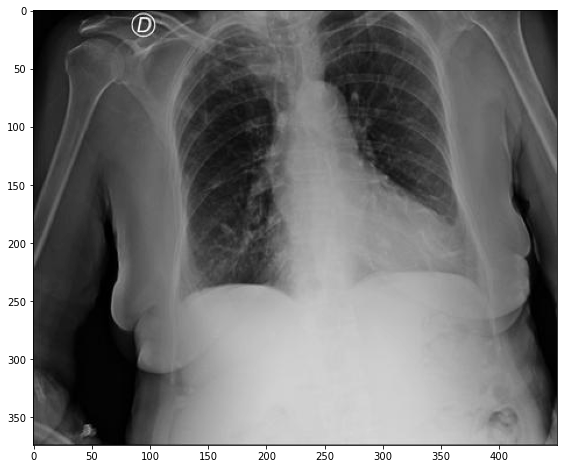

---------------------------------------------------------------


In [91]:
# datos de estudio a analizar

jpg_file_name = '6534a837497d.jpg'

red_subfix = '_red'

red_jpg_file_name = jpg_file_name.replace('.jpg', red_subfix+'.jpg')

dir = './data/examples/train_jpg/'

# cargamos imagen original y reducida de un estudio en JPG
jpgs = open_jpgs(jpg_file_name = jpg_file_name,
                red_jpg_file_name = red_jpg_file_name,
                dir = dir)

# almacenamos imagen ORIGINAL
jpg = jpgs[1]

# almacenamos imagen REUCIA
jpg_red = jpgs[3]

# calculo de relacion entre imagen original y la escalada
scale = jpg_red.size[0]/jpg.size[0]

# muestra resultado
#print('Ruta completa de imagen original:', jpgs[0])
#print('Ruta completa de imagen reucida:', jpgs[2])
#print(' El porcentaje de escalado es aproximadamente:', round(scale,3)*100)

# visualizamos dataframe con recuadros con diagnóstico
vis_diag_box(jpg_file_name)

# visualizamos JPG REDUCIDO con recuadros con diagnóstico
vis_diag_jpg(file_name = red_jpg_file_name,
                scale = scale,
                red_subfix = '_red',
                dir = dir)

Box 0: x, y, w, h: 116, 102, 53, 104
Box 1: x, y, w, h: 330, 137, 53, 93
Tamaño de imagen: (376, 450, 3)
JPG reducido modificado.
Ruta de imagen: ./data/examples/train_jpg/
ID estudio: 65761e66de9f_red.jpg


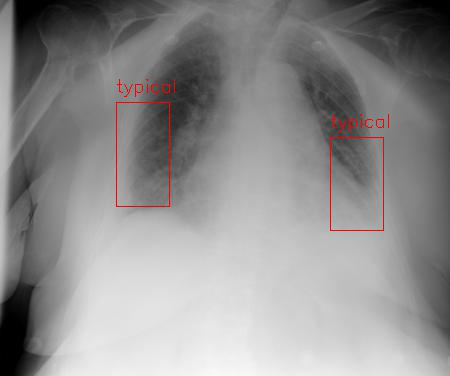

In [92]:
# datos de estudio a analizar

jpg_file_name = '65761e66de9f.jpg'

red_subfix = '_red'

red_jpg_file_name = jpg_file_name.replace('.jpg', red_subfix+'.jpg')

dir = './data/examples/train_jpg/'

# cargamos imagen original y reducida de un estudio en JPG
jpgs = open_jpgs(jpg_file_name = jpg_file_name,
                red_jpg_file_name = red_jpg_file_name,
                dir = dir)

# almacenamos imagen ORIGINAL
jpg = jpgs[1]

# almacenamos imagen REUCIA
jpg_red = jpgs[3]

# calculo de relacion entre imagen original y la escalada
scale = jpg_red.size[0]/jpg.size[0]

# muestra resultado
#print('Ruta completa de imagen original:', jpgs[0])
#print('Ruta completa de imagen reucida:', jpgs[2])
#print(' El porcentaje de escalado es aproximadamente:', round(scale,3)*100)

# visualizamos dataframe con recuadros con diagnóstico
vis_diag_box(jpg_file_name)

# visualizamos JPG REDUCIDO con recuadros con diagnóstico
vis_diag_jpg(file_name = red_jpg_file_name,
                scale = scale,
                red_subfix = '_red',
                dir = dir)

Box 0: x, y, w, h: 720, 636, 332, 648
Box 1: x, y, w, h: 2044, 847, 329, 576
Tamaño de imagen: (2330, 2783, 3)
JPG original modificado.
Ruta de imagen: ./data/examples/train_jpg/
ID estudio: 65761e66de9f.jpg


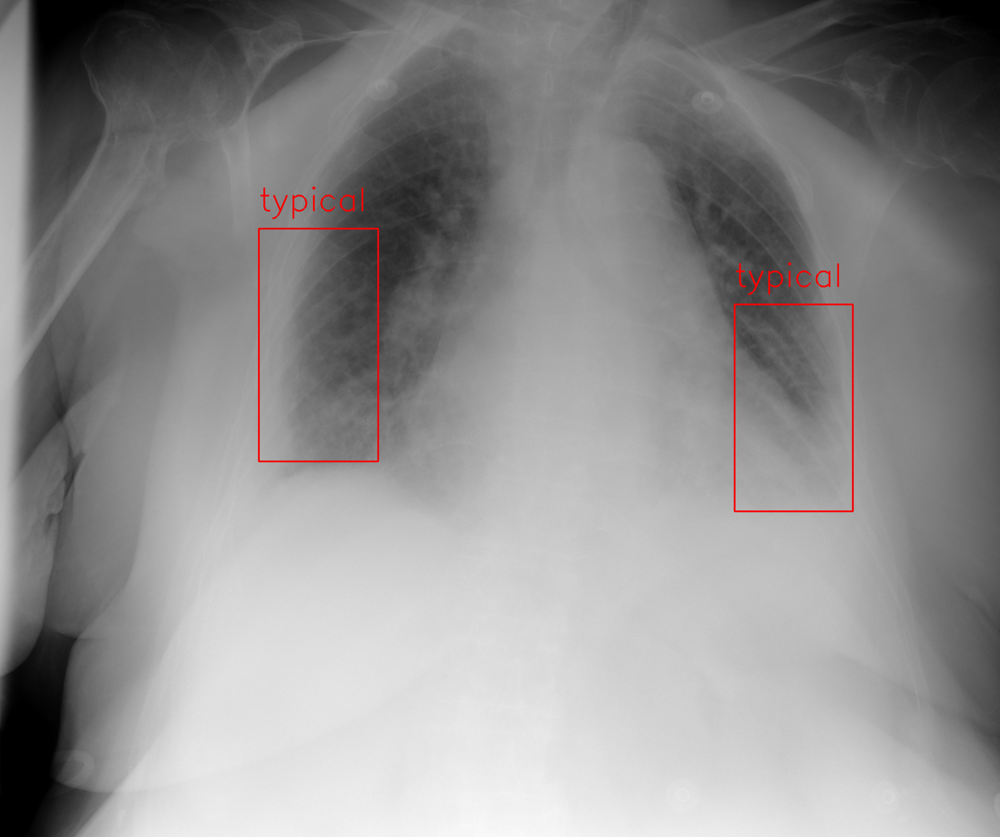

In [93]:
# datos de estudio a analizar

jpg_file_name = '65761e66de9f.jpg'

red_subfix = '_red'

red_jpg_file_name = jpg_file_name.replace('.jpg', red_subfix+'.jpg')

dir = './data/examples/train_jpg/'

# cargamos imagen original y reducida de un estudio en JPG
jpgs = open_jpgs(jpg_file_name = jpg_file_name,
                red_jpg_file_name = red_jpg_file_name,
                dir = dir)

# almacenamos imagen ORIGINAL
jpg = jpgs[1]

# almacenamos imagen REUCIA
jpg_red = jpgs[3]

# calculo de relacion entre imagen original y la escalada
scale = jpg_red.size[0]/jpg.size[0]

# muestra resultado
#print('Ruta completa de imagen original:', jpgs[0])
#print('Ruta completa de imagen reucida:', jpgs[2])
#print(' El porcentaje de escalado es aproximadamente:', round(scale,3)*100)

# visualizamos dataframe con recuadros con diagnóstico
vis_diag_box(jpg_file_name)

# visualizamos JPG REDUCIDO con recuadros con diagnóstico
vis_diag_jpg(file_name = jpg_file_name,
                scale = scale,
                red_subfix = '_red',
                dir = dir)

Imagen reducida correctamente.
Box 0: x, y, w, h: 320, 165, 63, 73
Box 1: x, y, w, h: 121, 195, 45, 58
Box 2: x, y, w, h: 124, 42, 29, 64
Tamaño de imagen: (374, 450, 3)
JPG reducido modificado.
Ruta de imagen: ./data/examples/train_jpg/
ID estudio: 74077a8e3b7c_red.jpg


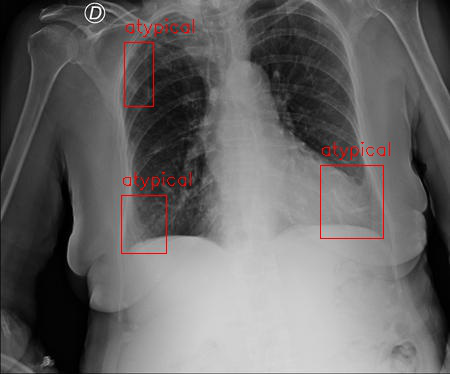

In [94]:
# datos de estudio a analizar

jpg_file_name = '74077a8e3b7c.jpg'

red_subfix = '_red'

red_jpg_file_name = jpg_file_name.replace('.jpg', red_subfix+'.jpg')

dir = './data/examples/train_jpg/'

# reducimos una imagen JPG y pasamos a escala de grises
reduce_jpg(dir = dir,
                jpg_file_name = jpg_file_name,
                output_basewidth = 450,
                output_subfix = red_subfix,
                return_jpg_red = False)

# cargamos imagen original y reducida de un estudio en JPG
jpgs = open_jpgs(jpg_file_name = jpg_file_name,
                red_jpg_file_name = red_jpg_file_name,
                dir = dir)
# almacenamos imagen ORIGINAL
jpg = jpgs[1]

# almacenamos imagen REDUCIDA
jpg_red = jpgs[3]

# calculo de relacion entre imagen original y la escalada
scale = jpg_red.size[0]/jpg.size[0]

# muestra resultado
#print('Ruta completa de imagen original:', jpgs[0])
#print('Ruta completa de imagen reucida:', jpgs[2])
#print(' El porcentaje de escalado es aproximadamente:', round(scale,3)*100)

# visualizamos dataframe con recuadros con diagnóstico
vis_diag_box(jpg_file_name)

# visualizamos JPG REDUCIDO con recuadros con diagnóstico
vis_diag_jpg(file_name = red_jpg_file_name,
                scale = scale,
                red_subfix = '_red',
                dir = dir)

Imagen reducida correctamente.
Box 0: x, y, w, h: 2175, 1123, 432, 500
Box 1: x, y, w, h: 823, 1324, 306, 394
Box 2: x, y, w, h: 845, 291, 201, 437
Tamaño de imagen: (2544, 3056, 3)
JPG original modificado.
Ruta de imagen: ./data/examples/train_jpg/
ID estudio: 74077a8e3b7c.jpg


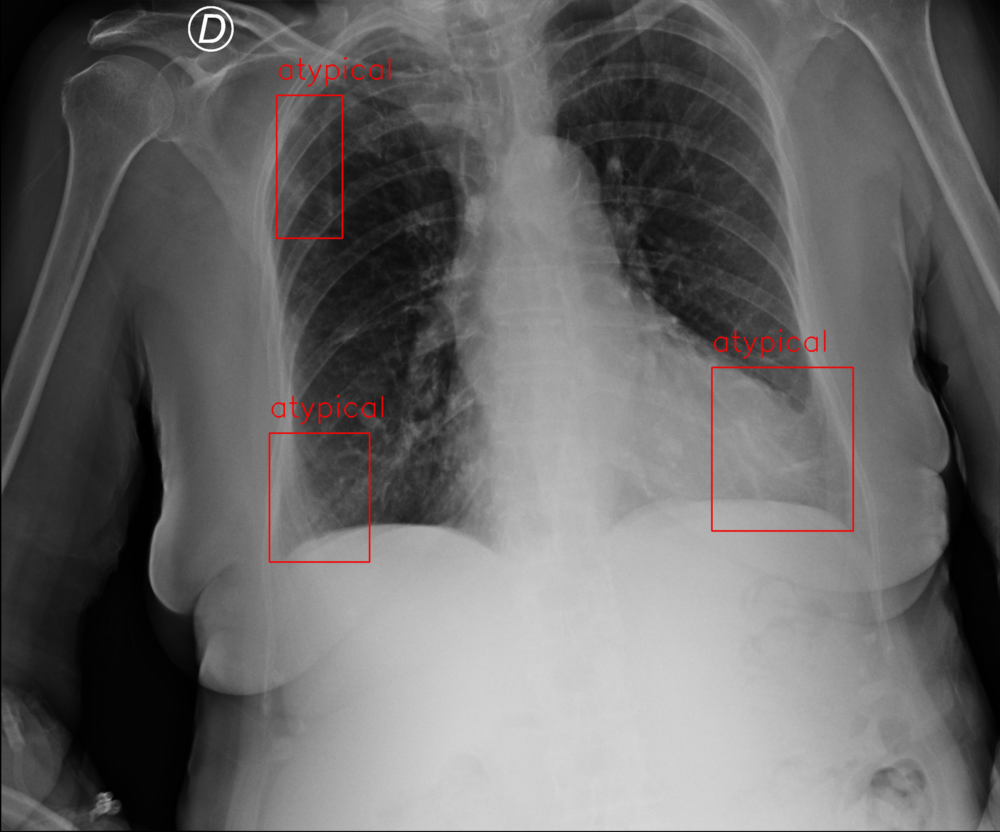

In [95]:
# datos de estudio a analizar

jpg_file_name = '74077a8e3b7c.jpg'

red_subfix = '_red'

red_jpg_file_name = jpg_file_name.replace('.jpg', red_subfix+'.jpg')

dir = './data/examples/train_jpg/'

# reducimos una imagen JPG y pasamos a escala de grises
reduce_jpg(dir = dir,
                jpg_file_name = jpg_file_name,
                output_basewidth = 450,
                output_subfix = red_subfix,
                return_jpg_red = False)

# cargamos imagen original y reducida de un estudio en JPG
jpgs = open_jpgs(jpg_file_name = jpg_file_name,
                red_jpg_file_name = red_jpg_file_name,
                dir = dir)
# almacenamos imagen ORIGINAL
jpg = jpgs[1]

# almacenamos imagen REDUCIDA
jpg_red = jpgs[3]

# calculo de relacion entre imagen original y la escalada
scale = jpg_red.size[0]/jpg.size[0]

# muestra resultado
#print('Ruta completa de imagen original:', jpgs[0])
#print('Ruta completa de imagen reucida:', jpgs[2])
#print(' El porcentaje de escalado es aproximadamente:', round(scale,3)*100)

# visualizamos dataframe con recuadros con diagnóstico
vis_diag_box(jpg_file_name)

# visualizamos JPG REDUCIDO con recuadros con diagnóstico
vis_diag_jpg(file_name = jpg_file_name,
                scale = scale,
                red_subfix = '_red',
                dir = dir)

### Conclusión

Respecto al análisis simultáneo de imágenes y dataframes, se observa que la información dada en los dataframes nos ayudaría a mejorar la predicción dado que nos podríamos enfocar en las áreas de diagnóstico recuadradas. En un primer caso no exploraremos esta información con el propósito de poner un modelo inicial en producción, modelos posteriores podrán contar con esta información.

---
## Exportamos `df.csv` para análisis general de datos

In [96]:
if not os.path.exists('./data/processed/df.csv'):
    # exportamos el CSV creado
    df.to_csv('./data/processed/df.csv', index = False)
else:
    print('Archivo existente')

Archivo existente


---
# Preparación de datos 1: Conversión de datos de estudio

### Conversión de `dcm` en `.\data\train` a `jpg` en `.\data\train_jpg`

In [97]:
# definimos carpeta de destino `train_jpg`
train_jpg_folder_path = "./data/train_jpg/"

# verificasimos si existe carpeta de destino sino es creada
if not os.path.exists(train_jpg_folder_path):
    os.makedirs(train_jpg_folder_path)

# verificamos que existan archivos en carpeta de destino sino realizamos la conversión
if not os.listdir(train_jpg_folder_path):
    print("Convirtiendo imágenes...")
    # creacion de contadores
    count_total = 0 # count total number of files
    count_new = 0 # count of new files
    # bucle para covertir archivos
    for row_index, image_name in df[['image_name_jpg']].iterrows(): # row_index: observation index, image_name: observation image name
        is_image_name_aux = df['image_name_jpg']==image_name[0] # is_image_name: image_name without extension
        dcm_full_dir_aux = df[is_image_name_aux]['full_dir'].item() # directory of original DCM file
        jpg_full_dir_aux = train_jpg_folder_path+df[is_image_name_aux]['image_name_jpg'].item() # directory of output JPG file
        count_total += 1
        if not os.path.exists(jpg_full_dir_aux): # Actions if JPG file does not exist
            count_new += 1
            ds_aux = dicom.dcmread(dcm_full_dir_aux) # read DCM file
            pixel_array_numpy_aux = ds_aux.pixel_array # calculate pixel array
            scaled_img_aux = cv2.convertScaleAbs(pixel_array_numpy_aux-np.min(pixel_array_numpy_aux), alpha=(255.0 / min(np.max(pixel_array_numpy_aux)-np.min(pixel_array_numpy_aux), 10000))) # scaling of image
            cv2.imwrite(jpg_full_dir_aux, scaled_img_aux) # save new scaled JPG file

    # muestra resultados
    print('Directorio "JPG train" contiene {} imágenes.'.format(count_total))
    print('{} imágenes fueron convertidas en esta sesión.'.format(count_new))
else:
    print('Directorio "JPG train" contiene {} imágenes convertidas anteriormente.'.format(len(os.listdir(train_jpg_folder_path))))

Directorio "JPG train" contiene 6334 imágenes convertidas anteriormente.


### Conversión de `dcm` en `.\data\test` a `jpg` en `.\data\test_jpg`

In [98]:
# definimos carpeta de origen
test_dcm_folder_path = "./data/test/"

# definimos carpeta de destino `test_jpg`
test_jpg_folder_path = "./data/test_jpg/"

# verificasimos si existe carpeta de destino sino es creada
if not os.path.exists(test_jpg_folder_path):
    os.makedirs(test_jpg_folder_path)

# creacion de contadores y lista auxiliar
count_total = 0 # count total number of files
test_walk_list = []

# verificamos que existan archivos en carpeta de destino sino realizamos la conversión
if not os.listdir(test_jpg_folder_path):
    print("Convirtiendo imágenes...")
    
    # carga de datos de carpetas, subcarpetas y archivos de un dado directorio
    for root, directories, files in os.walk(test_dcm_folder_path, topdown=False):
        test_walk_list.append(root)
        
    # creacion de un dataframe con los datos obtenidos
    df_root_folders = pd.DataFrame(test_walk_list)
    df_root_folders[0] = df_root_folders[0].str.replace('\\', '/', regex=True)
    df_root_folders[['relative','data','test','root', 'dir']] = df_root_folders[0].str.split('/', expand=True)
    df_root_folders = df_root_folders[['root']].drop_duplicates()

    # bucle de conversión
    for row_index, folder_name in df_root_folders[['root']].iterrows():
        count_total += 1
        input_dir = test_dcm_folder_path+folder_name[0]
        conv_dcm_to_jpg(input_dir = input_dir,
                        output_dir = test_jpg_folder_path,
                        return_jpg=False)

# muestra resultados
num_files_aux = len(os.listdir(test_jpg_folder_path))
print('Directorio "JPG test" contiene {} imágenes convertidas.'.format(num_files_aux))
print('{} imágenes fueron convertidas en esta sesión.'.format(count_total))

Directorio "JPG test" contiene 1263 imágenes convertidas.
0 imágenes fueron convertidas en esta sesión.


### Conclusión

En esta sección comenzamos creando una carpeta train_jpg para almacenar todos los datos de entrenamiento justamente en formato jpg. Por medio de un bucle convertimos cada imagen dcm del dataframe global. Posteriormente dividiremos estos archivos datos de entrenamiento y validación respetando una proporción con 20% de datos de validación.
Para los datos de test realizamos el mismo ejercicio, pero en una carpeta denominada test_jpg.


---
# GPU

## Tensorflow / Keras

In [99]:
# datos de GPU
physical_device = tf.config.experimental.list_physical_devices('GPU')
print(f'Númeor de GPUs encontradas: {len(physical_device)}')
print(f'Identificación de GPU encontrada: {physical_device}')

Númeor de GPUs encontradas: 1
Identificación de GPU encontrada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [100]:
# Seteo de GPU para entrenamiento (TensorFlow >= 2.11 no usa GPU en Windows nativo)
if physical_device:
    tf.config.experimental.set_memory_growth(physical_device[0],True)

    # Verificamos si se utiliza para entrenamiento
    print(f'GPU utilizada para entrenamiento: {tf.config.experimental.get_memory_growth(physical_device[0])}')
else:
    print('No se encontró GPU para TensorFlow; se usará CPU.')

GPU utilizada para entrenamiento: True


## Pytorch / CUDA

In [101]:
import torch

In [ ]:
# datos de GPU
print(f'Númeor de GPUs encontradas: {torch.cuda.device_count()}')

# Verificamos si se utiliza para entrenamiento
print(f'GPUs disponible para entrenamiento: {torch.cuda.is_available()}')

# Seteo de GPU para entrenamiento
print(f'ID de GPUs disponible para entrenamiento: {torch.cuda.current_device()}')

In [103]:
# Verificamos caracteríticas de GPU
torch.cuda.device(0)

In [ ]:
# Verificamos caracteríticas de GPU
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 3070 Laptop GPU'

In [ ]:
### usamos GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# result
device

device(type='cuda')

In [106]:
### usamos GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# result
device

device(type='cpu')

### Conclusión

Tanto Tensorflow como Pytorch nos permiten utilizar como recurso de procesamiento al GPU. En esta sección verificamos que el GPU esté disponible y asignado para entrenamiento en los dos frameworks.
Utilizar el GPU es muy necesario dado que trabajaremos con muchas imágenes, no sólo las imágenes de los estudios sino también las creada para aumentación de los datos. La aumentación es necesaria para mejorar los modelos ya que éstos se entrenan con más y diferentes ejemplos de las mismas imágenes que ya tenemos clasificadas.


---
# Modelo 1: ImageDataGenerator

## Preprocesado

In [107]:
# directorio que contine las imágenes
directory = './data/train_jpg/' #train_jpg_folder_path

# columna del dataframe que contiene el nombre de las imágenes
x_col = 'image_name_jpg'

# columna del dataframe que contiene la clasificación de las imágenes
y_col = 'diagnostic_cat'

# tramaño final de imágenes a reducir por el Image Data Generator
n_max_pixel = 64

# colores finales de las imágenes a reducir por el Image Data Generator
color_mode = 'grayscale'

# tamaño de batches de data
batch_size = 500

# reescalado de imágenes a reducir por el Image Data Generator 
rescale=1./255

## Train / Test split

In [108]:
# tamaño de train/test
train_val_size = 0.2

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_1_keras/data/model_1_df_train.csv'):
    # train / val split
    model_1_df_train, model_1_df_val = model_selection.train_test_split(df[['image_name_jpg','diagnostic_cat']],
                                                                        test_size=train_val_size,
                                                                        random_state=123,
                                                                        shuffle=True)
    # exportamos el csv creado
    model_1_df_train.to_csv('./experiments/model_1_keras/data/model_1_df_train.csv', index=False)
    model_1_df_val.to_csv('./experiments/model_1_keras/data/model_1_df_val.csv', index=False)
else:
    # cargamos dataframe
    model_1_df_train = pd.read_csv('./experiments/model_1_keras/data/model_1_df_train.csv')
    model_1_df_val = pd.read_csv('./experiments/model_1_keras/data/model_1_df_val.csv')

print("Los datos de entrenamiento son:", model_1_df_train.shape[0])
print("Los datos de validación son:", model_1_df_val.shape[0])

Los datos de entrenamiento son: 5067
Los datos de validación son: 1267


In [109]:
pd.DataFrame({
    # Frecuencias absolutas de categorías de datos de entrenamiento
    'Train_frec_categorías': model_1_df_train['diagnostic_cat'].value_counts(),
    
    # porcentaje por categoría de datos de entrenamiento
    'Train_porc_categorías': (model_1_df_train['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    # Frecuencias absolutas de categorías de datos de validación
    'Val_frec_categorías': model_1_df_val['diagnostic_cat'].value_counts(),
    
    # porcentaje por categoría de datos de validación
    'Val_porc_categorías': (model_1_df_val['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

,Train_frec_categorías,Train_porc_categorías,Val_frec_categorías,Val_porc_categorías
typical,2376,46.89,631,49.80
neg_for_pneumonia,1406,27.75,330,26.05
indeterminate,899,17.74,209,16.50
atypical,386,7.62,97,7.66


In [110]:
# creacion del Image Data Generator genérico
data_generator_1 = ImageDataGenerator(rescale = rescale)

# creacion del Image Data Generator para datos de training
train_generator_1 = data_generator_1.flow_from_dataframe(dataframe = model_1_df_train,
                                                        directory = directory, 
                                                        x_col =  x_col,
                                                        y_col = y_col,
                                                        batch_size = batch_size,
                                                        seed = 123,
                                                        shuffle = True,
                                                        class_mode = 'categorical',
                                                        target_size = (n_max_pixel, n_max_pixel), 
                                                        color_mode = color_mode
                                                        )

# creacion del Image Data Generator para datos de validación
val_generator_1 = data_generator_1.flow_from_dataframe(dataframe = model_1_df_val,
                                                        directory = directory, 
                                                        x_col =  x_col,
                                                        y_col = y_col,
                                                        batch_size = batch_size,
                                                        seed = 123,
                                                        shuffle = True,
                                                        class_mode = 'categorical',
                                                        target_size = (n_max_pixel, n_max_pixel), 
                                                        color_mode = color_mode
                                                        )

Found 5067 validated image filenames belonging to 4 classes.
Found 1267 validated image filenames belonging to 4 classes.


In [111]:
# clases del image data generator
print(train_generator_1.class_indices)

print(val_generator_1.class_indices)

{'atypical': 0, 'indeterminate': 1, 'neg_for_pneumonia': 2, 'typical': 3}
{'atypical': 0, 'indeterminate': 1, 'neg_for_pneumonia': 2, 'typical': 3}


## Tensorboard

In [112]:
# Cargamos TensorBoard
%load_ext tensorboard

# borramos logs de modelos pre-existentes
#!rm -rf ./experiments/model_1_keras/logs/

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [113]:
# definimos directorio de logs de modelo
log_dir = "./experiments/model_1_keras/logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

# cargamos función callback para almacenamiento de datos
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

## Modelo

In [114]:
# argumentos para capa inicial de modelo
input_shape = (n_max_pixel, n_max_pixel, 1)

# modelo CCN
model_1 = Sequential([
        Dense(32, input_shape=input_shape),
        Activation('relu'),
        Dense(64),
        Activation('relu'),
        Flatten(),
        Dense(128),
        Activation('relu'),
        Dropout(0.5),
        Dense(4),
        Activation('softmax')
        ])

# compilación de modelo
model_1.compile(optimizers.RMSprop(learning_rate=0.001, decay=1e-6),
                loss="categorical_crossentropy",
                metrics=["accuracy"])

In [115]:
# muestra modelo creado
model_1.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64, 64, 32)        64        
_________________________________________________________________
activation (Activation)      (None, 64, 64, 32)        0         
_________________________________________________________________
dense_1 (Dense)              (None, 64, 64, 64)        2112      
_________________________________________________________________
activation_1 (Activation)    (None, 64, 64, 64)        0         
_________________________________________________________________
flatten (Flatten)            (None, 262144)            0         
_________________________________________________________________
dense_2 (Dense)              (None, 128)               33554560  
_________________________________________________________________
activation_2 (Activation)    (None, 128)               0

In [116]:
# argumentos para entrenamiento de modelo
step_size_train_1 = train_generator_1.n//train_generator_1.batch_size
step_size_val_1  = val_generator_1.n//val_generator_1.batch_size

In [117]:
# definimos ubicacion para guardar modelos
model_1_dir = "./experiments/model_1_keras/"
model_2_dir = "./experiments/model_2_keras/"

# creamos carpetas si no existen
for model_dir in (model_1_dir, model_2_dir):
    if not os.path.exists(model_dir):
        os.makedirs(model_dir)

In [118]:
# verificamos si existe un modelo previamente entrenado
model_1_hist_file_json = model_1_dir+'model_1_history.json' 
model_1_hist_file_csv = model_1_dir+'model_1_history.csv'
    
if not os.path.exists(model_1_dir+'model_1_img_data_gen.h5'):
    # entrenamiento de modelo
    model_1_history = model_1.fit(x = train_generator_1,
                                    steps_per_epoch = step_size_train_1,
                                    validation_data = val_generator_1,
                                    validation_steps = step_size_val_1,
                                    epochs=20,
                                    callbacks=[tensorboard_callback])
    
    # guardamos modelo
    model_1.save(model_1_dir+'model_1_img_data_gen.h5')
    
    # convertimos entrenamiento en dataframe     
    model_1_history_df = pd.DataFrame(model_1_history.history) 
    
    # guardamos datos de entrenamiento en formato JSON
    with open(model_1_hist_file_json, 'wb') as handle: # saving the history of the model
        pickle.dump(model_1_history.history, handle)
        model_1_loaded = False
        
    # guardamos datos de entrenamiento en formato CSV
    model_1_history_df.to_csv(model_1_hist_file_csv, index = False)
    
else:
    model_1_loaded = True
    print('Modelo 1 entrenado en sesión anterior.')


Modelo 1 entrenado en sesión anterior.


## Evaluación

In [119]:
# histórico de accuracy y losses   
if model_1_loaded == True:
    # abrimos histórico en formato JSON
    with open(model_1_hist_file_json, 'rb') as handle: 
        model_1_history = pickle.load(handle)
    
    # abrimos histórico en formato CSV
    #model_1_history = pd.read_csv('model_1_hist_file_csv')
        
    tf_acc = model_1_history['accuracy']
    tf_val_acc = model_1_history['val_accuracy']
    tf_loss = model_1_history['loss']
    tf_val_loss = model_1_history['val_loss']
else:
    tf_acc = model_1_history.history['accuracy']
    tf_val_acc = model_1_history.history['val_accuracy']
    tf_loss = model_1_history.history['loss']
    tf_val_loss = model_1_history.history['val_loss']
    
    # comprobamos accuracy de modelo basandonos en los datos de validation
    model_1.evaluate(x = val_generator_1, steps = step_size_val_1)


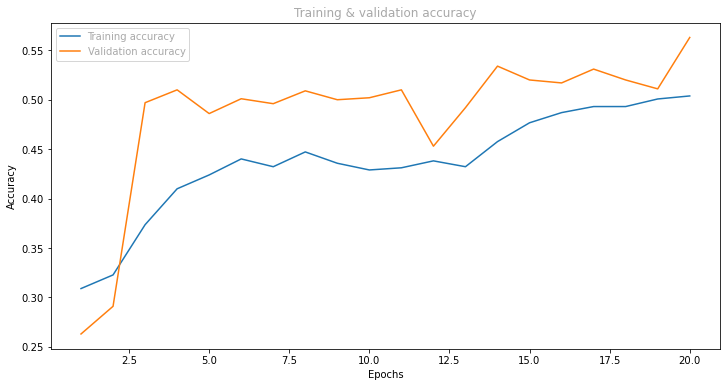

In [120]:
# definimos cantidad de epochs 
tf_epochs = range(1, len(tf_acc) + 1)

# parámetros de gráfico
plt.figure(figsize=(12, 6))

# plot de accuracy de entrenamiento
plt.plot(tf_epochs, tf_acc, label='Training accuracy')

# plot de accuracy de test
plt.plot(tf_epochs, tf_val_acc, label='Validation accuracy')

# visualización
plt.title('Training & validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

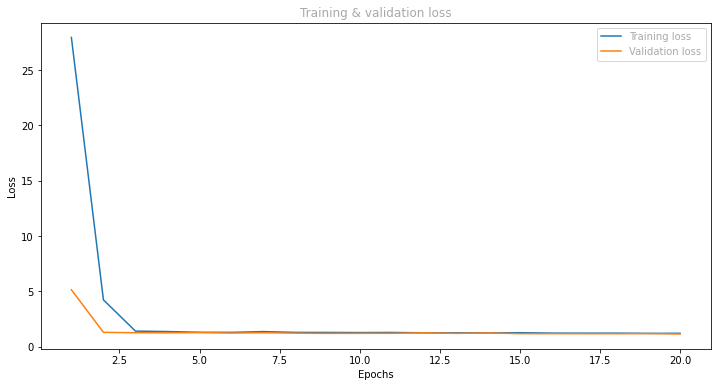

In [121]:
# parámetros de gráfico
plt.figure(figsize=(12, 6))

# plot de loss de entrenamiento
plt.plot(tf_epochs, tf_loss, label='Training loss')

# plot de loss de test
plt.plot(tf_epochs, tf_val_loss, label='Validation loss')

# visualización
plt.title('Training & validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [122]:
if not os.path.exists('./experiments/model_1_keras/data/model_1_df_val_eval.csv'):    
    
    # cálculo de probabilida de predicciones
    model_1_pred_val = model_1.predict(val_generator_1)

    # muestra probabilida de predicciones de datos de validación
    model_1_df_val_pred = pd.DataFrame(pd.DataFrame(model_1_pred_val, columns=val_generator_1.class_indices))

    # muestra predicciones de datos de validación (mayor probabilidad)
    model_1_df_val_pred['diagnostic_cat_pred'] = model_1_df_val_pred.idxmax(axis=1)

    # unimos dataframes para evaluación
    model_1_df_val_eval = pd.concat([model_1_df_val.reset_index(), model_1_df_val_pred], axis = 1)

    # quitamos columnas no relevantes
    model_1_df_val_eval = model_1_df_val_eval.drop(columns = ['index'])
    
    # exportamos CSV
    model_1_df_val_eval.to_csv('./experiments/model_1_keras/data/model_1_df_val_eval.csv', index = False)

else:
    # cargamos dataframe
    model_1_df_val_eval = pd.read_csv('./experiments/model_1_keras/data/model_1_df_val_eval.csv')

# muestra resultados
model_1_df_val_eval

,image_name_jpg,diagnostic_cat,atypical,indeterminate,neg_for_pneumonia,typical,diagnostic_cat_pred
0,81eb2ea84b8a.jpg,typical,0.050482,0.155095,0.238207,0.556216,typical
1,6728e11290af.jpg,typical,0.095664,0.184367,0.273753,0.446216,typical
2,7064823e0cf2.jpg,atypical,0.042731,0.149076,0.227795,0.580398,typical
3,c2e09dcc6455.jpg,atypical,0.089055,0.169380,0.188724,0.552841,typical
4,685114c3c9fd.jpg,typical,0.085467,0.177042,0.233838,0.503653,typical
...,...,...,...,...,...,...,...
1262,4123a71d9796.jpg,typical,0.090566,0.179033,0.353639,0.376763,typical
1263,8111093dcda1.jpg,typical,0.045433,0.153184,0.240671,0.560712,typical
1264,279bde1a7b20.jpg,neg_for_pneumonia,0.049674,0.156321,0.240117,0.553888,typical
1265,23c05cf9e8e0.jpg,typical,0.071452,0.166228,0.218592,0.543729,typical


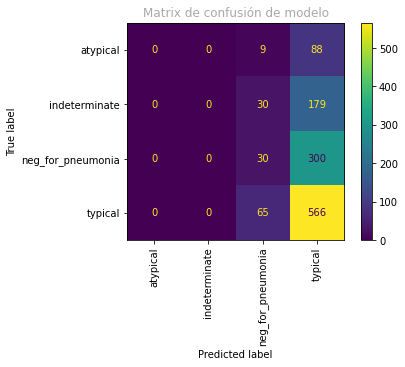

<Figure size 576x576 with 0 Axes>

Reporte de clasificación de modelo:
                   precision    recall  f1-score   support

         atypical       0.00      0.00      0.00        97
    indeterminate       0.00      0.00      0.00       209
neg_for_pneumonia       0.22      0.09      0.13       330
          typical       0.50      0.90      0.64       631

         accuracy                           0.47      1267
        macro avg       0.18      0.25      0.19      1267
     weighted avg       0.31      0.47      0.35      1267




<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [123]:
# creamos matriz de confusion
conf_mat_1 = confusion_matrix(y_true=model_1_df_val_eval['diagnostic_cat'],
                                y_pred = model_1_df_val_eval['diagnostic_cat_pred'])

# mostramos matriz de confusion
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat_1, display_labels=['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical'])
disp.plot(xticks_rotation='vertical')
plt.title('Matrix de confusión de modelo')
plt.figure(figsize = (8,8))
plt.show()

# muestra reporte de modelo de clasificación supervisado
print(f"Reporte de clasificación de modelo:\n"
        f"{classification_report(y_true=model_1_df_val_eval['diagnostic_cat'], y_pred = model_1_df_val_eval['diagnostic_cat_pred'])}\n")

## Conclusión

Primero realizamos la división de datos de entrenamiento y test en dos dataframes y verificamos que las proporciones de las clases se mantengan en ambos grupos.

Luego creamos Image Data Generators a través de los dataframes de entrenamiento y validación creados. Esto es necesario dado que para el modelado  es necesario contar con datos numéricos, es decir una representación de las imágenes en tensores y además, esta función produce aumentación de los datos.
Características del Image Data Generator:
- Tamaño final de imágenes a reducir: n_max_pixel = 64
- Colores finales de las imágenes a reducir: color_mode = 'grayscale'
- Tamaño de batches de datos: batch_size = 500
- Reescalado de imágenes a reducir: rescale=1./255

Luego creamos la red neuronal. Las características del modelo de redes neuronales que crearemos son las siguientes:

- Capas: Utilizamos Dense layers (conexión profunda) y flatten layers (aplanamiento en una dimensión) para calcular los pesos o weights y preservar su orden. Las dropout layers (marginado) nos ayudan a evitar overfitting. Luego de cada capa Dense utilizamos como función de activación la ReLu a excepción de la última layer que debe ser de múltiple clasificación, por lo que utilizamos la función de activación softmax.
- Función de costes: Se selecciona categorical_crossentropy como loss function a utilizar considerando que estamos ante un problema de clasificación múltiple.
- Optimizador: Se selecciona RMSprop como optimizador. La tasa de aprendizaje o learning rate utilizado es considerablemente bajo para obtener los mínimos valores de la loss function. Esto no es un problema para este caso ya que no es necesario que el aprendizaje del modelo tarde algunas horas.

El modelo inicial mostró un accuracy aceptable de aproximadamente 55% pero que debe ser mejorado para que la solución final sea útil y rentable. Se muestra a continuación la gráfica de accuracy de los datos de entrenamiento y validación dónde se observa una mejora al incrementar las epochs. Esto nos indica que el modelo inicial deberá entrenarse con gran cantidad de epochs para maximizar el accuracy.

Los valores de loss fueron disminuyendo tanto para los datos de entrenamiento como de validación al incrementar el número de epochs por lo que en este caso también conviene tener un gran número de epochs en un modelo futuro.

El modelo inicial predice una probabilidad de clasificar cada imagen en un tipo de clase. Esto es lo mismo que indicar cuánto se asemeja cada imagen a cada clase logrando que el resultado final siempre sume 1 entre todas las clases (100% de probabilidad). En el caso del modelo inicial este muestra los siguientes valores para los algunos de los estudios de validación predichos.

La matriz de confusión claramente muestra que el modelo tiene una cierta dificultad para predecir valores que no sean típicos debido al gran desbalance de los datos y es por esto que logra un f-1 score de 0.47 aprox. En esencia, estamos ante un problema de desbalanceo de datos.

---
# Preparación de datos 2: Limpieza de datos

## Comparación de imágenes individuales

In [124]:
# creamos función de preparación de imágenes
def image_prep(dir = './data/examples/train_jpg/',
                img = '6534a837497d_red.jpg',
                width = 450,
                height = 375):
    """Función para cargar una imágen y prepararla para comparación.

    Args:
        dir (str, optional): ruta a ubicació de archivo de imagen JPG.. Defaults to './data/examples/train_jpg/'.
        img (str, optional): nombre de archivo con extensión.. Defaults to '6534a837497d_red.jpg'.
        width (int, optional): ancho de la imágen preparada.. Defaults to 450.
        height (int, optional): alto de la imágen preparada.. Defaults to 375.

    Returns:
        [cv2 image]: imagen CV2 en escala de grises y con tamaño ajustado.
    """
    
    # cargamos la imagen
    img_full_dir = dir+img
    img = cv2.imread(img_full_dir)
    
    # transformamos a escala de grises
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # convertimos las dimensiones de la imagen
    img = cv2.resize(img, (width, height), interpolation = cv2.INTER_AREA)
    
    return img

In [125]:
# creamos función de cálculo de de MSE entre 2 imágenes
def mse_calc(imageA,
        imageB):
	"""Función que calcula el error cuadrático medio (Mean Squared Error) entre 2 imágenes. Esto es la suma del cuadrado de las diferencias entre las 2 imágenes.
	Las imágenes deben tener la misma dimensión.

	Args:
		imageA ([cv2_image]): Imágen 1 a comparar.
		imageB ([cv2_image]): Imágen 2 a comparar.

	Returns:
		[num]: MSE. Mientras más bajo el error, más similares son las imágenes entre si.
	"""
	err = np.sum((imageA.astype("float") - imageB.astype("float")) ** 2)
	err /= float(imageA.shape[0] * imageA.shape[1])
	
	return err

In [126]:
# creamos función de comparación entre imágenes
def compare_images(imageA,
                    imageB,
                    show_images = False):
	"""Función para comparar imágenes por medio del error cuadrático medio y el índice de similaridad de estructura.

	Args:
		imageA ([cv2 image]): imagen original a comparar.
		imageB ([cv2 image]): imagen 2 a comparar.
		show_images (bool, optional): True: muestra imágenes. Defaults to False.
	"""
    # cálculo de errores y similitud entre imágenes
	mse_value = mse_calc(imageA, imageB).round(4)
	ssim_value = ssim(imageA, imageB).round(4)
	if show_images == True:
		# seteo de figura
		fig = plt.figure(figsize=(10,4))
		fig.suptitle('Comparación de imágenes')
		plt.title("MSE: %.2f - SSIM: %.2f" % (mse_value, ssim_value))
		plt.axis('off')
		# muestra 1ra imagen
		ax = fig.add_subplot(1, 2, 1)
		plt.title("Original")
		plt.imshow(imageA, cmap = plt.cm.gray, aspect='auto')
		plt.axis("off")
		# muestra 2da imagen
		ax = fig.add_subplot(1, 2, 2)
		plt.imshow(imageB, cmap = plt.cm.gray, aspect='auto')
		plt.axis("off")
		# show the images
		plt.show()
	
	return mse_value, ssim_value

In [127]:
# seleccionamos imágenes de prueba a comparar
img_original = image_prep(dir = './data/examples/train_jpg/',
                img = '6534a837497d_red.jpg',
                width = 450,
                height = 375)

img_to_comp = image_prep(dir = './data/examples/train_jpg/',
                img = '65761e66de9f_red.jpg',
                width = 450,
                height = 375)

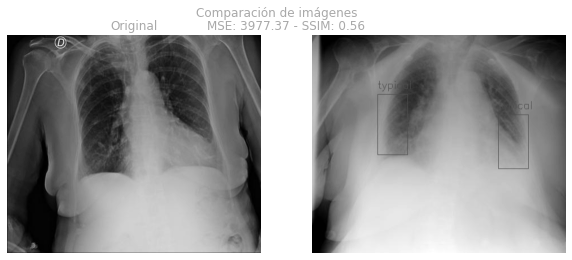

(3977.3724, 0.5553)

In [128]:
# comparamos imágenes
compare_images(img_original, img_to_comp, show_images= True)

In [129]:
# comparamos imágenes
print('La diferencia entre la imagen original y la comparada es, en porcentaje, aproximadamente:',
        compare_images(img_original, img_to_comp, show_images= False)[1]*100)


La diferencia entre la imagen original y la comparada es, en porcentaje, aproximadamente: 55.53


## Comparación de imágenes en directorio

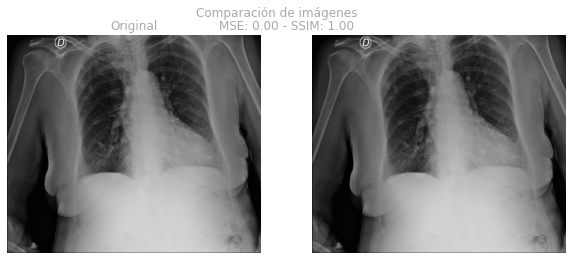

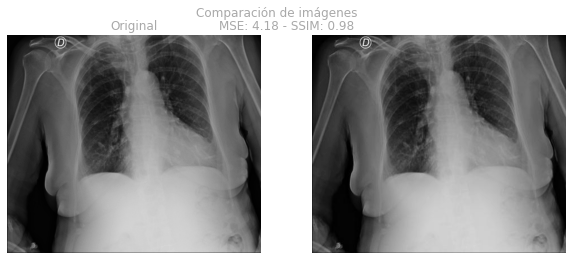

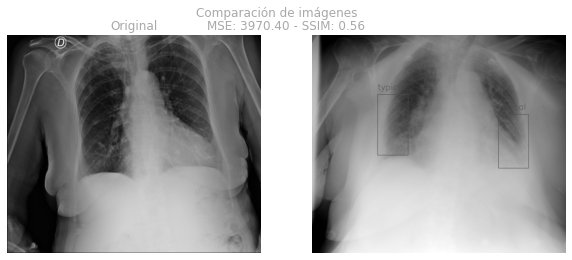

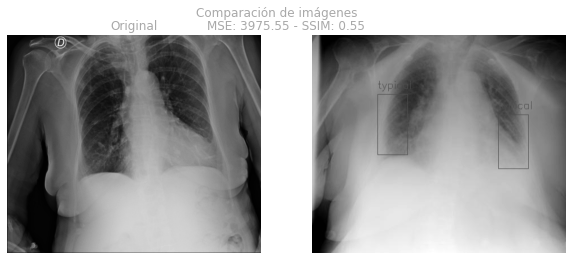

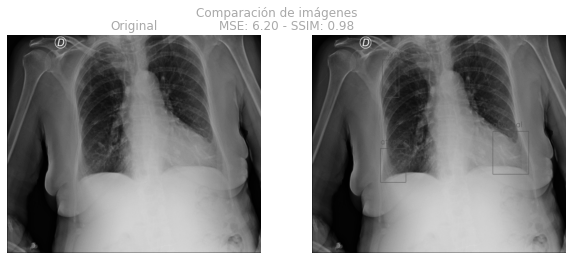

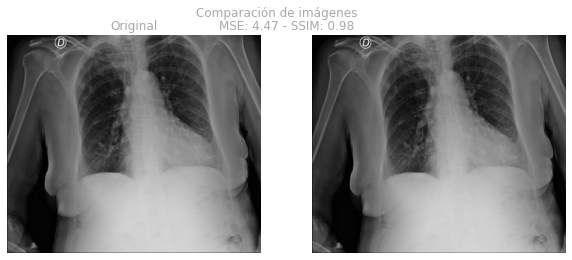

In [130]:
# datos de imagen original a comparar
dir = './data/examples/train_jpg/'
template = '6534a837497d.jpg'
width = 450
height = 375

# cargamos imagen
img_original = image_prep(dir = dir,
                img = template,
                width = width,
                height = height)

# creacion de contadores
count_total = 0 # count total number of files

# bucle de comparación
for root, directories, files in os.walk(dir, topdown=False):
    for name in files:
        img_to_comp = image_prep(dir = dir,
                                    img = name,
                                    width = width,
                                    height = height)
        compare_images(img_original, img_to_comp, show_images= True)

In [131]:
if not os.path.exists('./data/processed/df_cleaned.csv'):
    # datos de imagen original a comparar
    dir = './data/train_jpg/'
    template = '000a312787f2.jpg'
    width = 450
    height = 375

    # cargamos imagen
    img_original = image_prep(dir = dir,
                    img = template,
                    width = width,
                    height = height)

    # creacion de contadores
    count_total = 0 # count total number of files

    # bucle de comparación de template con estudios del dataframe
    for row_index, image_name in df[['image_name_jpg']].iterrows(): # row_index: observation index, image_name: observation image name
        img_to_comp = image_prep(dir = dir,
                                    img = image_name[0],
                                    width = width,
                                    height = height)
        df.loc[df['image_name_jpg']==image_name[0],['comparison']] = compare_images(img_original,
                                                                                                        img_to_comp,
                                                                                                        show_images= False)[1]
        count_total += 1

    # muestra resultados
    print('Directorio JPG train folder contiene {} imágenes que fueron comparadas.'.format(count_total))
    
    df_cleaned = df
    
else:
    # cargamos dataframe
    df_cleaned = pd.read_csv('./data/processed/df_cleaned.csv')

In [132]:
# mostramos datos a filtrar
df_cleaned.iloc[:5]

,study_dir,full_dir,boxes,label,StudyInstanceUID,diagnostic_cat,image_name_jpg,comparison
0,00086460a852,./data/train/00086460a852/9e8302230c91/65761e6...,"[{'x': 720.65215, 'y': 636.51048, 'width': 332...",opacity 1 720.65215 636.51048 1052.84563 1284....,00086460a852,typical,65761e66de9f.jpg,0.5709
1,000c9c05fd14,./data/train/000c9c05fd14/e555410bd2cd/51759b5...,NaN,none 1 0 0 1 1,000c9c05fd14,atypical,51759b5579bc.jpg,0.4531
2,00292f8c37bd,./data/train/00292f8c37bd/73120b4a13cb/f6293b1...,NaN,none 1 0 0 1 1,00292f8c37bd,neg_for_pneumonia,f6293b1c49e2.jpg,0.4507
3,005057b3f880,./data/train/005057b3f880/e34afce999c5/3019399...,NaN,none 1 0 0 1 1,005057b3f880,neg_for_pneumonia,3019399c31f4.jpg,0.2650
4,0051d9b12e72,./data/train/0051d9b12e72/152f6ec68d86/bb4b1da...,"[{'x': 812.54698, 'y': 1376.41291, 'width': 62...",opacity 1 812.54698 1376.41291 1435.14793 1806...,0051d9b12e72,atypical,bb4b1da810f3.jpg,0.3243


In [133]:
df_comparison_threshold = pd.DataFrame({
    # Datos de imágenes totales
    'Comparison_sin_filtro': df_cleaned['comparison'].describe(),
    
    # Datos de imágenes por debajo del threshold definido
    'Filtro_10%': df_cleaned.loc[df_cleaned['comparison']>=0.1, 'comparison'].describe(),
    
    # Datos de imágenes por debajo del threshold definido
    'Filtro_20%': df_cleaned.loc[df_cleaned['comparison']>=0.2, 'comparison'].describe(),
    
    # Datos de imágenes por debajo del threshold definido
    'Filtro_30%': df_cleaned.loc[df_cleaned['comparison']>=0.3, 'comparison'].describe(),
    
    # Datos de imágenes por debajo del threshold definido
    'Filtro_40%': df_cleaned.loc[df_cleaned['comparison']>=0.4, 'comparison'].describe(),
    
    # Datos de imágenes por debajo del threshold definido
    'Filtro_50%': df_cleaned.loc[df_cleaned['comparison']>=0.5, 'comparison'].describe(),
    
    })

# muestra resultados
df_comparison_threshold

,Comparison_sin_filtro,Filtro_10%,Filtro_20%,Filtro_30%,Filtro_40%,Filtro_50%
count,6334.000000,6334.000000,6308.000000,5957.000000,4736.000000,1790.000000
mean,0.445951,0.445951,0.447087,0.457535,0.483225,0.526324
std,0.078096,0.078096,0.076209,0.064497,0.042532,0.021826
min,0.120600,0.120600,0.204000,0.300100,0.400000,0.500100
25%,0.399200,0.399200,0.400400,0.413900,0.451375,0.512900
50%,0.462750,0.462750,0.463250,0.468700,0.486100,0.519900
75%,0.505800,0.505800,0.505900,0.508800,0.517400,0.536900
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


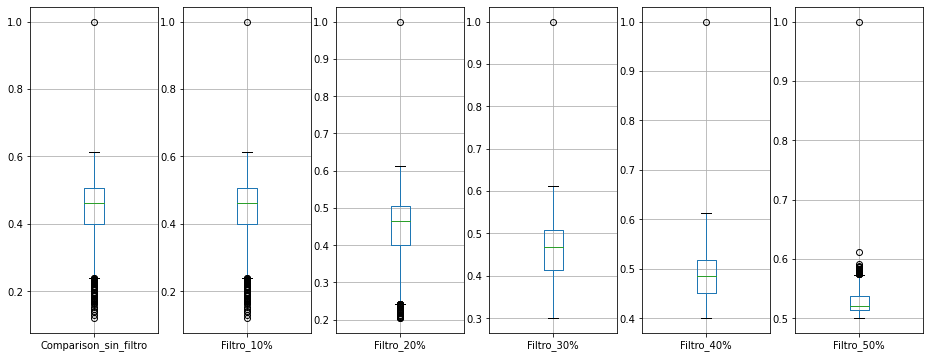

In [134]:
# parámetros de gráfico
fig_boxplot, axes_boxplot = plt.subplots(1,6, figsize=(16, 6))

# creamos gráficos
count = 0 
for filt in np.arange(0,0.6,0.1):
    col_name = df_comparison_threshold.columns.values[count]
    aux_boxplot = df_cleaned.loc[df_cleaned['comparison']>=filt, ['comparison']].rename(columns = {'comparison': col_name}).boxplot(ax=axes_boxplot.flatten()[count])
    count += 1
    
# mostramos resultados
plt.show()

## Conclusión

Se concluye entonces para la limpieza de datos que es posible quitar imágenes que no se parezcan lo suficiente a una imagen original y aún así contaríamos con varias imágenes para entrenamiento. Al dejar todas las imágenes se observa (primer boxplot) que existen imágenes muy distintas a la original (outliers) por debajo de aproximadamente 0.25 ó 25% de similitud. Para eliminar todos los outliers debemos filtrar imágenes con similitud menor al 30% ó 40%. Si filtramos imágenes que son cercanas al 50% de similitud entonces ya estamos quitando buenos datos de entrenamiento. 

---
## Exportamos `df_cleaned.csv` para visualización y modelo 2

In [135]:
if not os.path.exists('./data/processed/df_cleaned.csv'):
    # exportamos el csv creado
    df_cleaned.to_csv('./data/processed/df_cleaned.csv', index = False)
else:
    print('Archivo existente')

Archivo existente


---
# Modelo 2: Improved ImageDataGenerator

## Preprocesado

In [136]:
# directorio que contine las imágenes
directory = './data/train_jpg/' #train_jpg_folder_path

# columna del dataframe que contiene el nombre de las imágenes
x_col = 'image_name_jpg'

# columna del dataframe que contiene la clasificación de las imágenes
y_col = 'diagnostic_cat'

# tramaño final de imágenes a reducir por el Image Data Generator
n_max_pixel = 64

# colores finales de las imágenes a reducir por el Image Data Generator
color_mode = 'grayscale'

# tamaño de batches de data
batch_size = 500

# reescalado de imágenes a reducir por el Image Data Generator 
rescale=1./255

## Train / Test split

In [137]:
# tamaño de train/test
train_val_size = 0.2
comparison_threshold = 0.4

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_2_keras/data/model_2_df_train.csv'):
    # train / val split
    model_2_df_train, model_2_df_val = model_selection.train_test_split(df_cleaned.loc[df_cleaned['comparison']>=comparison_threshold, ['image_name_jpg','diagnostic_cat']],
                                                                        test_size=train_val_size,
                                                                        random_state=123,
                                                                        shuffle=True,
                                                                        stratify=df_cleaned.loc[df_cleaned['comparison']>=comparison_threshold, ['diagnostic_cat']])
    # exportamos el csv creado
    model_2_df_train.to_csv('./experiments/model_2_keras/data/model_2_df_train.csv', index=False)
    model_2_df_val.to_csv('./experiments/model_2_keras/data/model_2_df_val.csv', index=False)
else:
    # cargamos dataframe
    model_2_df_train = pd.read_csv('./experiments/model_2_keras/data/model_2_df_train.csv')
    model_2_df_val = pd.read_csv('./experiments/model_2_keras/data/model_2_df_val.csv')

print("Los datos de entrenamiento son:", model_2_df_train.shape[0])
print("Los datos de validación son:", model_2_df_val.shape[0])

Los datos de entrenamiento son: 3788
Los datos de validación son: 948


In [138]:
pd.DataFrame({
    # Frecuencias absolutas de categorías de datos de entrenamiento
    'Train_frec_categorías': model_2_df_train['diagnostic_cat'].value_counts(),
    
    # porcentaje por categoría de datos de entrenamiento
    'Train_porc_categorías': (model_2_df_train['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    # Frecuencias absolutas de categorías de datos de validación
    'Val_frec_categorías': model_2_df_val['diagnostic_cat'].value_counts(),
    
    # porcentaje por categoría de datos de validación
    'Val_porc_categorías': (model_2_df_val['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

,Train_frec_categorías,Train_porc_categorías,Val_frec_categorías,Val_porc_categorías
typical,1762,46.52,441,46.52
neg_for_pneumonia,1056,27.88,264,27.85
indeterminate,677,17.87,169,17.83
atypical,293,7.73,74,7.81


In [139]:
# creacion del Image Data Generator genérico
data_generator_2 = ImageDataGenerator(rescale = rescale)

# creacion del Image Data Generator para datos de training
train_generator_2 = data_generator_2.flow_from_dataframe(dataframe = model_2_df_train,
                                                        directory = directory, 
                                                        x_col =  x_col,
                                                        y_col = y_col,
                                                        batch_size = batch_size,
                                                        seed = 123,
                                                        shuffle = True,
                                                        class_mode = 'categorical',
                                                        target_size = (n_max_pixel, n_max_pixel), 
                                                        color_mode = color_mode
                                                        )

# creacion del Image Data Generator para datos de validación
val_generator_2 = data_generator_2.flow_from_dataframe(dataframe = model_2_df_val,
                                                        directory = directory, 
                                                        x_col =  x_col,
                                                        y_col = y_col,
                                                        batch_size = batch_size,
                                                        seed = 123,
                                                        shuffle = True,
                                                        class_mode = 'categorical',
                                                        target_size = (n_max_pixel, n_max_pixel), 
                                                        color_mode = color_mode
                                                        )

Found 3788 validated image filenames belonging to 4 classes.
Found 948 validated image filenames belonging to 4 classes.


In [140]:
# clases del image data generator
print(train_generator_2.class_indices)

print(val_generator_2.class_indices)

{'atypical': 0, 'indeterminate': 1, 'neg_for_pneumonia': 2, 'typical': 3}
{'atypical': 0, 'indeterminate': 1, 'neg_for_pneumonia': 2, 'typical': 3}


## Tensorboard

In [141]:
# Cargamos TensorBoard
#%reload_ext tensorboard

# borramos logs de modelos pre-existentes
#!rm -rf ./experiments/model_2_keras/logs/

In [ ]:
# definimos directorio de logs de modelo
log_dir = "./experiments/model_2_keras/logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

# cargamos función callback para almacenamiento de datos
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

## Modelo

In [142]:
# argumentos para capa inicial de modelo
input_shape = (n_max_pixel, n_max_pixel, 1)

# modelo CCN
model_2 = Sequential([
        Dense(32, input_shape=input_shape),
        Activation('relu'),
        Dense(64),
        Activation('relu'),
        Flatten(),
        Dense(128),
        Activation('relu'),
        Dropout(0.5),
        Dense(4),
        Activation('softmax')
        ])

# compilación de modelo
model_2.compile(optimizers.RMSprop(learning_rate=0.001, decay=1e-6),
                loss="categorical_crossentropy",
                metrics=["accuracy"])

In [143]:
# muestra modelo creado
model_2.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_4 (Dense)              (None, 64, 64, 32)        64        
_________________________________________________________________
activation_4 (Activation)    (None, 64, 64, 32)        0         
_________________________________________________________________
dense_5 (Dense)              (None, 64, 64, 64)        2112      
_________________________________________________________________
activation_5 (Activation)    (None, 64, 64, 64)        0         
_________________________________________________________________
flatten_1 (Flatten)          (None, 262144)            0         
_________________________________________________________________
dense_6 (Dense)              (None, 128)               33554560  
_________________________________________________________________
activation_6 (Activation)    (None, 128)              

In [144]:
# argumentos para entrenamiento de modelo
step_size_train_2 = train_generator_2.n//train_generator_2.batch_size
step_size_val_2  = val_generator_2.n//val_generator_2.batch_size

In [145]:
# verificamos si existe un modelo previamente entrenado
model_2_hist_file_json = model_2_dir+'model_2_history.json' 
model_2_hist_file_csv = model_2_dir+'model_2_history.csv'

if not os.path.exists(model_2_dir+'model_2_img_data_gen.h5'):
    # entrenamiento de modelo
    model_2_history = model_2.fit(x = train_generator_2,
                            steps_per_epoch = step_size_train_2,
                            validation_data = val_generator_2,
                            validation_steps = step_size_val_2,
                            epochs=20,
                            callbacks=[tensorboard_callback])
    
    # guardamos modelo
    model_2.save(model_2_dir+'model_2_img_data_gen.h5')
    
    # convertimos entrenamiento en dataframe     
    model_2_history_df = pd.DataFrame(model_2_history.history) 
    
    # guardamos datos de entrenamiento en formato JSON
    with open(model_2_hist_file_json, 'wb') as handle: # saving the history of the model
        pickle.dump(model_2_history.history, handle)
        model_2_loaded = False
        
    # guardamos datos de entrenamiento en formato CSV
    model_2_history_df.to_csv(model_2_hist_file_csv, index = False)
    
else:
    model_2_loaded = True
    print('Modelo 2 entrenado en sesión anterior.')

Modelo 2 entrenado en sesión anterior.


## Evaluación

In [146]:
# histórico de accuracy y losses   
if model_2_loaded == True:
    # abrimos histórico en formato JSON
    with open(model_2_hist_file_json, 'rb') as handle: 
        model_2_history = pickle.load(handle)
    
    # abrimos histórico en formato CSV
    #model_2_history = pd.read_csv('model_2_hist_file_csv')
        
    tf_acc = model_2_history['accuracy']
    tf_val_acc = model_2_history['val_accuracy']
    tf_loss = model_2_history['loss']
    tf_val_loss = model_2_history['val_loss']
else:
    tf_acc = model_2_history.history['accuracy']
    tf_val_acc = model_2_history.history['val_accuracy']
    tf_loss = model_2_history.history['loss']
    tf_val_loss = model_2_history.history['val_loss']
    
    # comprobamos accuracy de modelo basandonos en los datos de validation
    model_2.evaluate(x = val_generator_2, steps = step_size_val_2)


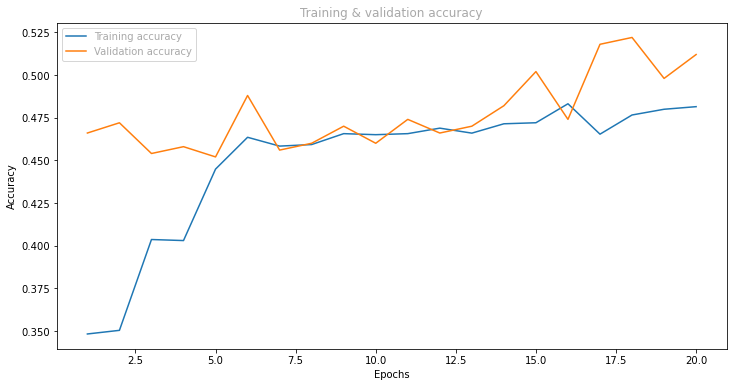

In [147]:
# definimos cantidad de epochs 
tf_epochs = range(1, len(tf_acc) + 1)

# parámetros de gráfico
plt.figure(figsize=(12, 6))

# plot de accuracy de entrenamiento
plt.plot(tf_epochs, tf_acc, label='Training accuracy')

# plot de accuracy de test
plt.plot(tf_epochs, tf_val_acc, label='Validation accuracy')

# visualización
plt.title('Training & validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

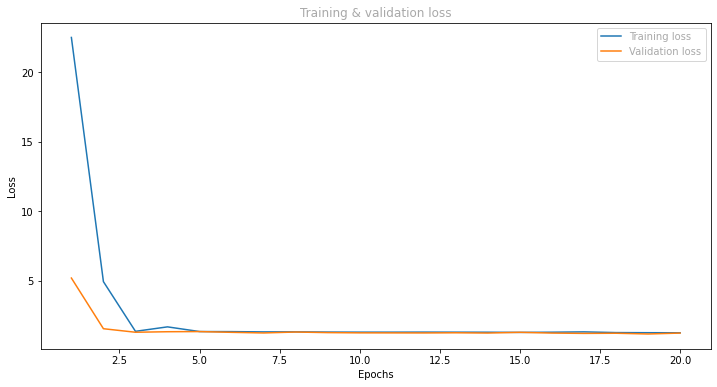

In [148]:
# parámetros de gráfico
plt.figure(figsize=(12, 6))

# plot de loss de entrenamiento
plt.plot(tf_epochs, tf_loss, label='Training loss')

# plot de loss de test
plt.plot(tf_epochs, tf_val_loss, label='Validation loss')

# visualización
plt.title('Training & validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [149]:
if not os.path.exists('./experiments/model_2_keras/data/model_2_df_val_eval.csv'):     
    
    # cálculo de probabilida de predicciones
    model_2_pred_val = model_2.predict(val_generator_2)
    
    # muestra probabilida de predicciones de datos de validación
    model_2_df_val_pred = pd.DataFrame(pd.DataFrame(model_2_pred_val, columns=val_generator_2.class_indices))

    # muestra predicciones de datos de validación (mayor probabilidad)
    model_2_df_val_pred['diagnostic_cat_pred'] = model_2_df_val_pred.idxmax(axis=1)

    # unimos dataframes para evaluación
    model_2_df_val_eval = pd.concat([model_2_df_val.reset_index(), model_2_df_val_pred], axis = 1)

    # quitamos columnas no relevantes
    model_2_df_val_eval = model_2_df_val_eval.drop(columns = ['index'])
    
    # exportamos CSV
    model_2_df_val_eval.to_csv('./experiments/model_2_keras/data/model_2_df_val_eval.csv', index = False)

else:
    # cargamos dataframe
    model_2_df_val_eval = pd.read_csv('./experiments/model_2_keras/data/model_2_df_val_eval.csv')


# muestra resultados
model_2_df_val_eval

,image_name_jpg,diagnostic_cat,atypical,indeterminate,neg_for_pneumonia,typical,diagnostic_cat_pred
0,ccdc93ecab12.jpg,typical,0.108180,0.179106,0.336500,0.376213,typical
1,ea4e6f4d1276.jpg,indeterminate,0.106464,0.191547,0.261342,0.440646,typical
2,0f501fe67203.jpg,typical,0.083736,0.175620,0.248689,0.491956,typical
3,04ee02f3b685.jpg,indeterminate,0.111749,0.177598,0.268377,0.442275,typical
4,5b8d34cda68e.jpg,typical,0.122764,0.181959,0.270622,0.424656,typical
...,...,...,...,...,...,...,...
943,b386bcbb0490.jpg,typical,0.131023,0.188135,0.347525,0.333317,neg_for_pneumonia
944,fdb8954398a5.jpg,typical,0.129473,0.204883,0.263178,0.402466,typical
945,bdbe3fa1b316.jpg,neg_for_pneumonia,0.119358,0.188674,0.312761,0.379206,typical
946,0c7b15362352.jpg,neg_for_pneumonia,0.110747,0.184860,0.314983,0.389410,typical


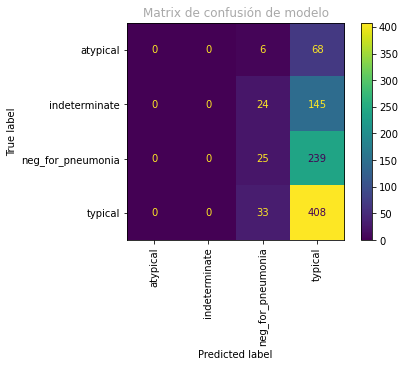

<Figure size 576x576 with 0 Axes>

Reporte de clasificación de modelo:
                   precision    recall  f1-score   support

         atypical       0.00      0.00      0.00        74
    indeterminate       0.00      0.00      0.00       169
neg_for_pneumonia       0.28      0.09      0.14       264
          typical       0.47      0.93      0.63       441

         accuracy                           0.46       948
        macro avg       0.19      0.25      0.19       948
     weighted avg       0.30      0.46      0.33       948




<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
<python_env>\lib\site-packages\sklearn\metrics\_classification.py:1308: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [150]:
# creamos matriz de confusion
conf_mat_2 = confusion_matrix(y_true=model_2_df_val_eval['diagnostic_cat'],
                                y_pred = model_2_df_val_eval['diagnostic_cat_pred'])

# mostramos matriz de confusion
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat_2, display_labels=['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical'])
disp.plot(xticks_rotation='vertical')
plt.title('Matrix de confusión de modelo')
plt.figure(figsize = (8,8))
plt.show()

# muestra reporte de modelo de clasificación supervisado
print(f"Reporte de clasificación de modelo:\n"
        f"{classification_report(y_true=model_2_df_val_eval['diagnostic_cat'], y_pred = model_2_df_val_eval['diagnostic_cat_pred'])}\n")

## Conclusiones

Primero realizamos la división de datos de entrenamiento y test en dos dataframes y verificamos que las proporciones de las clases se mantengan en ambos grupos.

Luego creamos Image Data Generators a través de los dataframes de entrenamiento y validación creados. Esto es necesario dado que para el modelado es necesario contar con datos numéricos, es decir una representación de las imágenes en tensores y, además, esta función produce aumentación de los datos.
Características del Image Data Generator:
- Tamaño final de imágenes a reducir: n_max_pixel = 64
- Colores finales de las imágenes a reducir: color_mode = 'grayscale'
- Tamaño de batches de datos: batch_size = 500
- Reescalado de imágenes a reducir: rescale=1./255

Las características del modelo de redes neuronales que crearemos son las siguientes:

- Capas: Utilizamos Dense layers (conexión profunda) y flatten layers (aplanamiento en una dimensión) para calcular los pesos o weights y preservar su orden. Las dropout layers (marginado) nos ayudan a evitar overfitting. Luego de cada capa Dense utilizamos como función de activación la ReLu a excepción de la última layer que debe ser de múltiple clasificación, por lo que utilizamos la función de activación softmax.
- Función de costes: Se selecciona categorical_crossentropy como loss function a utilizar considerando que estamos ante un problema de clasificación múltiple.
- Optimizador: Se selecciona RMSprop como optimizador. La tasa de aprendizaje o learning rate utilizado es considerablemente bajo para obtener los mínimos valores de la loss function. Esto no es un problema para este caso ya que no es necesario que el aprendizaje del modelo tarde algunas horas.

El modelo mostró un accuracy aceptable de aproximadamente 47% pero que debe ser mejorado para que la solución final sea útil y rentable. Se muestra a continuación la gráfica de accuracy de los datos de entrenamiento y validación dónde se observa una mejora al incrementar las epochs. Esto nos indica que el modelo inicial deberá entrenarse con gran cantidad de epochs para maximizar el accuracy.

Los valores de loss fueron disminuyendo tanto para los datos de entrenamiento como de validación al incrementar el número de epochs por lo que en este caso también conviene tener un gran número de epochs en un modelo futuro.

El modelo inicial predice una probabilidad de clasificar cada imagen en un tipo de clase. Esto es lo mismo que indicar cuánto se asemeja cada imagen a cada clase logrando que el resultado final siempre sume 1 entre todas las clases (100% de probabilidad). En el caso del modelo inicial este muestra los siguientes valores para los algunos de los estudios de validación predichos.

La matriz de confusión claramente muestra que el modelo tiene una cierta dificultad para predecir valores que no sean típicos nuevamente debido al gran desbalance de los datos y es por esto que logra un f-1 score de 0.46 aprox. En esencia, seguimos ante un problema de desbalanceo de datos. 

---
# Preparación de datos 3: Imputación y balanceo

## Preprocesado de dataframes

In [136]:
# creamos dataframe de datos pareados para modelo
df_cleaned_parsed = df_cleaned.copy()

In [137]:
# cantidad de datos sin informar
print('Total de datos sin informar:', len(df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, 'boxes']))

Total de datos sin informar: 2040


In [138]:
df_summary_before = pd.DataFrame({
    # porcentaje absoluto por categoría (datos sin informar e informados)
    'Porc._datos_totales': (df_cleaned_parsed['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos sin informar recuadro de diagnóstico
    'Porc._datos_sin_inf.': (df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos con recuadro de diagnóstico
    'Porc._datos_informados.': (df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==False, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

# análisis de datos limpios
print('Procentajes de frecuencias de categorías ANTES de transformaciones.')
df_summary_before

Procentajes de frecuencias de categorías ANTES de transformaciones.


,Porc._datos_totales,Porc._datos_sin_inf.,Porc._datos_informados.
atypical,7.63,4.51,9.11
indeterminate,17.49,2.89,24.43
neg_for_pneumonia,27.41,85.10,NaN
typical,47.47,7.50,66.46


In [139]:
# transformamos valores faltantes por la categoría más frecuente y definimos recuadro de 1 pixel
df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, ['diagnostic_cat']] = 'neg_for_pneumonia'
df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, ['boxes']] = "[{'x': 0, 'y': 0, 'width': 1, 'height': 1}]"

# transformamos strings a listas para parseo de datos
df_cleaned_parsed['boxes'] = df_cleaned_parsed['boxes'].apply(eval)

In [141]:
# cantidad de datos sin informar
print('Total de datos sin informar:', len(df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, 'boxes']))

Total de datos sin informar: 0


In [140]:
df_summary_after = pd.DataFrame({
    # porcentaje absoluto por categoría (datos sin informar e informados)
    'Porc._datos_totales': (df_cleaned_parsed['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos sin informar recuadro de diagnóstico
    'Porc._datos_sin_inf.': (df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==True, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos con recuadro de diagnóstico
    'Porc._datos_informados.': (df_cleaned_parsed.loc[df_cleaned_parsed['boxes'].isna()==False, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

# análisis de datos limpios
print('Procentajes de frecuencias de categorías DESPUÉS de imputación de datos de recuadro.')
df_summary_after

Procentajes de frecuencias de categorías DESPUÉS de imputación de datos de recuadro.


,Porc._datos_totales,Porc._datos_sin_inf.,Porc._datos_informados.
atypical,6.17,NaN,6.17
indeterminate,16.56,NaN,16.56
neg_for_pneumonia,32.21,NaN,32.21
typical,45.06,NaN,45.06


In [142]:
# creamos dataframe con datos de bounding boxes parseados agrupados por estudio y recuadro diagnóstico
df_yolo = df_cleaned_parsed.groupby(['image_name_jpg', 'diagnostic_cat'])['boxes'].apply(lambda x: pd.DataFrame(x.values[0])).reset_index()

# renombramos columnas
df_yolo = df_yolo.rename(columns = {'image_name_jpg': 'filename',
                                    'diagnostic_cat': 'class',
                                    'x': 'xmin',
                                    'y': 'ymin'})

# creamos nuevas columnas de bounding box
df_yolo['xmax'] = df_yolo['xmin']+df_yolo['width'] 
df_yolo['ymax'] = df_yolo['ymin']+df_yolo['height'] 

# quitamos columnas redundantes
df_yolo = df_yolo.drop(columns=['level_2', 'width', 'height'])

In [143]:
if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo.csv'):
    
    # definimos directorio de imágenes a analizar
    dir = './data/train_jpg/' #train_jpg_folder_path

    # creamos variables auxiliares
    count_total = 0
    df_yolo['width'] = 0
    df_yolo['height'] = 0

    # bucle para tomar información de ancho y alto de cada imagen
    for root, directories, files in os.walk(dir, topdown=False):
        for name in files:
            img_full_dir = dir+str(name)
            img = cv2.imread(img_full_dir, 0)
            df_yolo.loc[df_yolo['filename']==name, ['width']] = img.shape[1]
            df_yolo.loc[df_yolo['filename']==name, ['height']] = img.shape[0]
            count_total += 1
            
    # exportamos el csv creado
    df_yolo.to_csv('./experiments/model_3_yolov5/data/df_yolo.csv', index = False)
else:
    # cargamos dataframe
    df_yolo = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo.csv')

In [144]:
# mostramos dataframe
df_yolo

,filename,class,xmin,ymin,xmax,ymax,width,height
0,000a312787f2.jpg,typical,789.28836,582.43035,1815.94498,2499.73327,4256,3488
1,000a312787f2.jpg,typical,2245.91208,591.20528,3340.57370,2352.75472,4256,3488
2,000c3a3f293f.jpg,neg_for_pneumonia,0.00000,0.00000,1.00000,1.00000,2832,2320
3,0012ff7358bc.jpg,typical,677.42216,197.97662,1545.21983,1197.75876,3056,2544
4,0012ff7358bc.jpg,typical,1792.69064,402.55250,2409.71798,1606.91050,3056,2544
...,...,...,...,...,...,...,...,...
9888,ffd9b6cf2961.jpg,typical,707.25199,722.07926,1099.39243,1571.26609,3050,2388
9889,ffdc682f7680.jpg,typical,2729.27083,332.26044,4225.52099,2936.84378,4256,3488
9890,ffdc682f7680.jpg,typical,1005.81250,1584.67711,1668.04163,2360.51048,4256,3488
9891,ffe942c8655f.jpg,typical,208.86463,91.53448,659.83210,719.58921,1387,1140


In [145]:
df_balanced_summary_before = pd.DataFrame({
    # # mostramos porcentaje de recuadros agrupadas por clases
    'Porcentaje': (df_yolo.groupby(['class'])['filename'].count()/ df_yolo['class'].count()*100).round(2),
    
    # mostramos cantidades de recuadros agrupadas por clases
    'Frecuencia': (df_yolo.groupby(['class'])['filename'].count()).round(2),
    
    })

df_balanced_summary_before

,Porcentaje,Frecuencia
class,,
atypical,5.43,537
indeterminate,14.51,1435
neg_for_pneumonia,20.62,2040
typical,59.45,5881


In [146]:
# agrupado de datos por clase
df_yolo_balanced = df_yolo.groupby('class')

# balanceo al mínimo de datos disponibles
df_yolo_balanced = pd.DataFrame(df_yolo_balanced[df_yolo.columns].apply(lambda x: x.sample(df_yolo_balanced.size().min()))).reset_index(drop=True)

In [147]:
df_balanced_summary_after = pd.DataFrame({
    # # mostramos porcentaje de recuadros agrupadas por clases
    'Porcentaje': (df_yolo_balanced.groupby('class').size()/df_yolo_balanced.groupby('class').size().sum()*100).round(2),
    
    # mostramos cantidades de recuadros agrupadas por clases
    'Frecuencia': df_yolo_balanced.groupby('class').size().round(2),
    
    })

df_balanced_summary_after

,Porcentaje,Frecuencia
class,,
atypical,25.0,537
indeterminate,25.0,537
neg_for_pneumonia,25.0,537
typical,25.0,537


## Preprocesado de imágenes

In [22]:
# definimos dimensiones de imágenes para modelo
height_resize = iaa.Sequential([ 
    iaa.Resize({"height": 600, "width": 'keep-aspect-ratio'})
])
width_resize = iaa.Sequential([ 
    iaa.Resize({"height": 'keep-aspect-ratio', "width": 600})
])

In [24]:
# función para convertir objeto BoundingBoxesOnImage en DataFrame
def bbs_obj_to_df(bbs_object):
#     convertimos BoundingBoxesOnImage objecto en array
    bbs_array = bbs_object.to_xyxy_array()
#     convertimos array a DataFrame ['xmin', 'ymin', 'xmax', 'ymax']
    df_bbs = pd.DataFrame(bbs_array, columns=['xmin', 'ymin', 'xmax', 'ymax'])
    return df_bbs

In [17]:
# creamos función para crear dataframe de recuadros con datos de aumentación de imágenes

def resize_imgaug(df, images_path, aug_images_path, image_prefix):
    # creamos dataframe que vamos a completar con información de imagen aumentada
    aug_bbs_xy = pd.DataFrame(columns=
                                ['filename','width','height','class', 'xmin', 'ymin', 'xmax', 'ymax']
                                )
    grouped = df.groupby('filename')    
    
    for filename in df['filename'].unique():
    # creamos dataframe separado agrupado por nombre de archivo
        group_df = grouped.get_group(filename)
        group_df = group_df.reset_index()
        group_df = group_df.drop(['index'], axis=1)
        
    # La única diferencia entre las if y elif a continuación es el uso de los aumentadores height_resize y width_resize
    # definido anteriormente.

    # Si la altura de la imagen es mayor o igual que el ancho de la imagen y más de 600 px realiza un aumento de tamaño que reduce la altura de la imagen a 600 px.
        if group_df['height'].unique()[0] >= group_df['width'].unique()[0] and group_df['height'].unique()[0] > 600:
            # cargamos imagen
            image = imageio.imread(images_path+filename)
            # tomamos coordenadas de recuadros y escribimos en array        
            bb_array = group_df.drop(['filename', 'width', 'height', 'class'], axis=1).values
            # pasar la matriz de coordenadas de cuadros delimitadores a la biblioteca imgaug
            bbs = BoundingBoxesOnImage.from_xyxy_array(bb_array, shape=image.shape)
            # aplicar aumento en la imagen y en los cuadros delimitadores
            image_aug, bbs_aug = height_resize(image=image, bounding_boxes=bbs)
            # escribe una imagen aumentada en un archivo
            imageio.imwrite(aug_images_path+image_prefix+filename, image_aug)  
            # crear un dataframe con valores aumentados de ancho y alto de la imagen
            info_df = group_df.drop(['xmin', 'ymin', 'xmax', 'ymax'], axis=1)        
            for index, _ in info_df.iterrows():
                info_df.at[index, 'width'] = image_aug.shape[1]
                info_df.at[index, 'height'] = image_aug.shape[0]
            # cambiar el nombre de los archivos agregando el prefijo predefinido
            info_df['filename'] = info_df['filename'].apply(lambda x: image_prefix+x)
            # crear undataframe con coordenadas de cuadros delimitadores aumentados utilizando la función que creamos anteriormente
            bbs_df = bbs_obj_to_df(bbs_aug)
            # concatenar toda la nueva información aumentada en un nuevo dataframe
            aug_df = pd.concat([info_df, bbs_df], axis=1)
            # agregar filas al dataframe aug_bbs_xy
            aug_bbs_xy = pd.concat([aug_bbs_xy, aug_df])
            
            
        # si el ancho de la imagen es mayor que la altura de la imagen Y más de 600 px, realice un aumento de tamaño que reduzca el ancho de la imagen a 600 px
        elif group_df['width'].unique()[0] > group_df['height'].unique()[0] and group_df['width'].unique()[0] > 600:
            # cargamos imagen
            image = imageio.imread(images_path+filename)
            # tomamos coordenadas de recuadros y escribimos en array          
            bb_array = group_df.drop(['filename', 'width', 'height', 'class'], axis=1).values
            # pasar la matriz de coordenadas de cuadros delimitadores a la biblioteca imgaug
            bbs = BoundingBoxesOnImage.from_xyxy_array(bb_array, shape=image.shape)
            # aplicar aumento en la imagen y en los cuadros delimitadores
            image_aug, bbs_aug = width_resize(image=image, bounding_boxes=bbs)
            # escribe una imagen aumentada en un archivo
            imageio.imwrite(aug_images_path+image_prefix+filename, image_aug)  
            # crear un dataframe con valores aumentados de ancho y alto de la imagen
            info_df = group_df.drop(['xmin', 'ymin', 'xmax', 'ymax'], axis=1)        
            for index, _ in info_df.iterrows():
                info_df.at[index, 'width'] = image_aug.shape[1]
                info_df.at[index, 'height'] = image_aug.shape[0]
            # cambiar el nombre de los archivos agregando el prefijo predefinido
            info_df['filename'] = info_df['filename'].apply(lambda x: image_prefix+x)
            # crear undataframe con coordenadas de cuadros delimitadores aumentados utilizando la función que creamos anteriormente
            bbs_df = bbs_obj_to_df(bbs_aug)
            # concatenar toda la nueva información aumentada en un nuevo dataframe
            aug_df = pd.concat([info_df, bbs_df], axis=1)
            # agregar filas al dataframe aug_bbs_xy
            aug_bbs_xy = pd.concat([aug_bbs_xy, aug_df])

        # agregar información de la imagen sin ningún cambio si la altura y el ancho son inferiores a 600 px
        else:
            aug_bbs_xy = pd.concat([aug_bbs_xy, group_df])
    # devuelve el dataframe con imágenes actualizadas y anotaciones de cuadros delimitadores
    aug_bbs_xy = aug_bbs_xy.reset_index()
    aug_bbs_xy = aug_bbs_xy.drop(['index'], axis=1)
    return aug_bbs_xy

In [151]:
# parámetros de función de preprocesado de imágenes
dir = './data/train_jpg/' #train_jpg_folder_path
red_images_path =  './data/train_jpg_red_aug/'
image_prefix = 'red_'

if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_resized.csv'):    
    # preprocesado de imágenes
    df_yolo_resized = resize_imgaug(df = df_yolo,
                                    images_path = dir,
                                    aug_images_path = red_images_path,
                                    image_prefix = image_prefix)
    # exportamos el csv creado
    df_yolo_resized.to_csv('./experiments/model_3_yolov5/data/df_yolo_resized.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_resized = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_resized.csv')

In [152]:
# parámetros de función de preprocesado de imágenes
dir = './data/train_jpg/' #train_jpg_folder_path
red_images_path =  './data/train_jpg_bal_red_aug/'
image_prefix = 'red_'

if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_balanced_resized.csv'):    
    # preprocesado de imágenes
    df_yolo_balanced_resized = resize_imgaug(df = df_yolo_balanced,
                                    images_path = dir,
                                    aug_images_path = red_images_path,
                                    image_prefix = image_prefix)
    # exportamos el csv creado
    df_yolo_balanced_resized.to_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_resized.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_balanced_resized = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_resized.csv')

In [18]:
# creamos una función para image augmentation

def image_aug(df, images_path, aug_images_path, image_prefix, augmentor):
    # crear un dataframe que vamos a completar con información de imagen aumentada
    aug_bbs_xy = pd.DataFrame(columns=
                                ['filename','width','height','class', 'xmin', 'ymin', 'xmax', 'ymax']
                                )
    grouped = df.groupby('filename')
    
    for filename in df['filename'].unique():
        # obtener un dataframe separado agrupado por nombre de archivo
        group_df = grouped.get_group(filename)
        group_df = group_df.reset_index()
        group_df = group_df.drop(['index'], axis=1)   
        # leer la imagen
        image = imageio.imread(images_path+filename)
        # obtener las coordenadas de los cuadros delimitadores y escribir en la matriz
        bb_array = group_df.drop(['filename', 'width', 'height', 'class'], axis=1).values
        # pasar la matriz de coordenadas de cuadros delimitadores a la biblioteca imgaug
        bbs = BoundingBoxesOnImage.from_xyxy_array(bb_array, shape=image.shape)
        # aplicar aumento en la imagen y en los cuadros delimitadores
        image_aug, bbs_aug = augmentor(image=image, bounding_boxes=bbs)
        # ignorar los cuadros delimitadores que se han caído del panel de la imagen
        bbs_aug = bbs_aug.remove_out_of_image()
        # recorta los cuadros delimitadores que están parcialmente fuera del panel de la imagen
        bbs_aug = bbs_aug.clip_out_of_image()
        
        # no realice ninguna acción con la imagen si no quedan cuadros delimitadores en ella  
        if re.findall('Image...', str(bbs_aug)) == ['Image([]']:
            pass
        
        # de lo contrario continuar
        else:
            # escribe una imagen aumentada en un archivo
            imageio.imwrite(aug_images_path+image_prefix+filename, image_aug)  
            # crear un dataframe con valores aumentados de ancho y alto de la imagen
            info_df = group_df.drop(['xmin', 'ymin', 'xmax', 'ymax'], axis=1)    
            for index, _ in info_df.iterrows():
                info_df.at[index, 'width'] = image_aug.shape[1]
                info_df.at[index, 'height'] = image_aug.shape[0]
            # cambiar el nombre de los archivos agregando el prefijo predefinido
            info_df['filename'] = info_df['filename'].apply(lambda x: image_prefix+x)
            # crear un dataframe con coordenadas de cuadros delimitadores aumentados utilizando la función que creamos anteriormente
            bbs_df = bbs_obj_to_df(bbs_aug)
            # concatenar toda la nueva información aumentada en un nuevo dataframe
            aug_df = pd.concat([info_df, bbs_df], axis=1)
            # agregar filas al dataframe aug_bbs_xy
            aug_bbs_xy = pd.concat([aug_bbs_xy, aug_df])            
    
    # devuelve el dataframe con imágenes actualizadas y anotaciones de cuadros delimitadores
    aug_bbs_xy = aug_bbs_xy.reset_index()
    aug_bbs_xy = aug_bbs_xy.drop(['index'], axis=1)
    return aug_bbs_xy

In [19]:
# parámetros de aumentación de imágenes
aug = iaa.SomeOf(2, [    
    iaa.Affine(scale=(0.5, 1.5)),
    iaa.Affine(rotate=(-60, 60)),
    iaa.Affine(translate_percent={"x":(-0.3, 0.3),"y":(-0.3, 0.3)}),
    iaa.Fliplr(1),
    iaa.Multiply((0.5, 1.5)),
    iaa.GaussianBlur(sigma=(1.0, 3.0)),
    iaa.AdditiveGaussianNoise(scale=(0.03*255, 0.05*255))
])

In [156]:
# parámetros de aumentación de imágenes
red_images_path =  './data/train_jpg_red_aug/'
aug_images_path = './data/train_jpg_red_aug/'
image_prefix = 'aug_'


if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_aug.csv'):    
    # creamos dataframe con datos de imágenes aumentadas
    df_yolo_aug = image_aug(df = df_yolo_resized,
                                    images_path = red_images_path,
                                    aug_images_path = aug_images_path,
                                    image_prefix = image_prefix,
                                    augmentor = aug)
    # exportamos el csv creado
    df_yolo_aug.to_csv('./experiments/model_3_yolov5/data/df_yolo_aug.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_aug = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_aug.csv')

In [158]:
# parámetros de aumentación de imágenes
red_images_path =  './data/train_jpg_bal_red_aug/'
aug_images_path = './data/train_jpg_bal_red_aug/'
image_prefix = 'aug_'


if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_balanced_aug.csv'):    
    # creamos dataframe con datos de imágenes aumentadas
    df_yolo_balanced_aug = image_aug(df = df_yolo_balanced_resized,
                                    images_path = red_images_path,
                                    aug_images_path = aug_images_path,
                                    image_prefix = image_prefix,
                                    augmentor = aug)
    # exportamos el csv creado
    df_yolo_balanced_aug.to_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_aug.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_balanced_aug = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_aug.csv')

---
## Exportamos `df_yolo_red_aug` y `df_yolo_balanced_red_aug` para modelos de Deep Learning

In [157]:
if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_red_aug.csv'):    
    # creamos dataframe con información de los recuadros de diagnóstico de imágenes reducidas y aumentadas para modelos de Deep Learning
    df_yolo_red_aug = pd.concat([df_yolo_resized, df_yolo_aug])
    # exportamos el csv creado
    df_yolo_red_aug.to_csv('./experiments/model_3_yolov5/data/df_yolo_red_aug.csv', index=False)
else:
    # cargamos dataframe
    df_yolo_red_aug = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_red_aug.csv')

In [159]:
if not os.path.exists('./experiments/model_3_yolov5/data/df_yolo_balanced_red_aug.csv'):    
    # creamos dataframe con información de los recuadros de diagnóstico de imágenes reducidas y aumentadas para modelos de Deep Learning
    df_yolo_balanced_red_aug = pd.concat([df_yolo_balanced_resized, df_yolo_balanced_aug])
    # exportamos el csv creado
    df_yolo_balanced_red_aug.to_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_red_aug.csv', index=False)
else:
    # cargamos dataframe
    df_yolo_balanced_red_aug = pd.read_csv('./experiments/model_3_yolov5/data/df_yolo_balanced_red_aug.csv')

---
# Modelo 3: YOLOv5

## Preprocesado

In [160]:
if not os.path.exists('./experiments/model_3_yolov5/yolov5/'):
    print('Descargando archivos de modelo YOLOv5.')
    !git clone https://github.com/ultralytics/yolov5 ./experiments/model_3_yolov5/yolov5
else:
    print('Directorio de modelo YOLOv5 existente.')

Directorio de modelo YOLOv5 existente.


In [161]:
# renombramos columnas para normalizado
df_yolo_norm = df_yolo_red_aug.copy().rename(columns={'width': 'red_img_width', 'height': 'red_img_height'}).dropna()

df_yolo_bal_norm = df_yolo_balanced_red_aug.copy().rename(columns={'width': 'red_img_width', 'height': 'red_img_height'}).dropna()

In [162]:
# mostramos dataframe
df_yolo_norm[:5]

,filename,red_img_width,red_img_height,class,xmin,ymin,xmax,ymax
0,red_000a312787f2.jpg,600,492,typical,111.271851,82.154739,256.007294,352.599976
1,red_000a312787f2.jpg,600,492,typical,316.622925,83.392487,470.945557,331.867920
2,red_000c3a3f293f.jpg,600,492,neg_for_pneumonia,0.000000,0.000000,0.211864,0.212069
3,red_0012ff7358bc.jpg,600,499,typical,133.001740,38.832680,303.380859,234.937759
4,red_0012ff7358bc.jpg,600,499,typical,351.968048,78.959785,473.112152,315.191956


In [163]:
# mostramos dataframe
df_yolo_bal_norm[:5]

,filename,red_img_width,red_img_height,class,xmin,ymin,xmax,ymax
0,red_ba91ca301cc2.jpg,600,559,atypical,407.661621,313.987061,539.345581,496.002197
1,red_8a89d61875f9.jpg,600,493,atypical,362.931702,212.944489,450.267212,298.807129
2,red_86484cc4db08.jpg,592,600,atypical,327.804047,301.737335,522.521484,469.023132
3,red_4fbc954682e8.jpg,600,499,atypical,341.575592,112.090073,565.969788,407.962402
4,red_589bc7a8c4ba.jpg,600,499,atypical,63.973701,157.713531,244.058243,422.092377


In [20]:
# creamos funciones de normalizado y nuevos parámetros para modelo
def width(df):
    return int(df.xmax - df.xmin)
def height(df):
    return int(df.ymax - df.ymin)
def x_center(df):
    return int(df.xmin + (df.width/2))
def y_center(df):
    return int(df.ymin + (df.height/2))
def w_norm(df):
    return df/img_width
def h_norm(df):
    return df/img_height

In [165]:
# definimos parámetros de normalizado
img_width = df_yolo_norm['red_img_width'].max()
img_height = df_yolo_norm['red_img_height'].max()

# utilizamos label encoder para tranformar clases a numérico
le = preprocessing.LabelEncoder()
le.fit(df_yolo_norm['class'])

print('Las clases de este modelo son:', le.classes_)

labels = le.transform(df_yolo_norm['class'])
df_yolo_norm['labels'] = labels

df_yolo_norm['width'] = df_yolo_norm.apply(width, axis=1)
df_yolo_norm['height'] = df_yolo_norm.apply(height, axis=1)

df_yolo_norm['x_center'] = df_yolo_norm.apply(x_center, axis=1)
df_yolo_norm['y_center'] = df_yolo_norm.apply(y_center, axis=1)

df_yolo_norm['x_center_norm'] = df_yolo_norm['x_center'].apply(w_norm)
df_yolo_norm['width_norm'] = df_yolo_norm['width'].apply(w_norm)

df_yolo_norm['y_center_norm'] = df_yolo_norm['y_center'].apply(h_norm)
df_yolo_norm['height_norm'] = df_yolo_norm['height'].apply(h_norm)

Las clases de este modelo son: ['atypical' 'indeterminate' 'neg_for_pneumonia' 'typical']


In [166]:
# definimos parámetros de normalizado
img_width = df_yolo_bal_norm['red_img_width'].max()
img_height = df_yolo_bal_norm['red_img_height'].max()

# utilizamos label encoder para tranformar clases a numérico
le = preprocessing.LabelEncoder()
le.fit(df_yolo_bal_norm['class'])

print('Las clases de este modelo son:', le.classes_)

labels = le.transform(df_yolo_bal_norm['class'])
df_yolo_bal_norm['labels'] = labels

df_yolo_bal_norm['width'] = df_yolo_bal_norm.apply(width, axis=1)
df_yolo_bal_norm['height'] = df_yolo_bal_norm.apply(height, axis=1)

df_yolo_bal_norm['x_center'] = df_yolo_bal_norm.apply(x_center, axis=1)
df_yolo_bal_norm['y_center'] = df_yolo_bal_norm.apply(y_center, axis=1)

df_yolo_bal_norm['x_center_norm'] = df_yolo_bal_norm['x_center'].apply(w_norm)
df_yolo_bal_norm['width_norm'] = df_yolo_bal_norm['width'].apply(w_norm)

df_yolo_bal_norm['y_center_norm'] = df_yolo_bal_norm['y_center'].apply(h_norm)
df_yolo_bal_norm['height_norm'] = df_yolo_bal_norm['height'].apply(h_norm)

Las clases de este modelo son: ['atypical' 'indeterminate' 'neg_for_pneumonia' 'typical']


In [167]:
# mostramos datos normalizados
df_yolo_norm

,filename,red_img_width,red_img_height,class,xmin,...,y_center,x_center_norm,width_norm,y_center_norm,height_norm
0,red_000a312787f2.jpg,600,492,typical,111.271851,...,217,0.305000,0.240000,0.361667,0.450000
1,red_000a312787f2.jpg,600,492,typical,316.622925,...,207,0.655000,0.256667,0.345000,0.413333
2,red_000c3a3f293f.jpg,600,492,neg_for_pneumonia,0.000000,...,0,0.000000,0.000000,0.000000,0.000000
3,red_0012ff7358bc.jpg,600,499,typical,133.001740,...,136,0.363333,0.283333,0.226667,0.326667
4,red_0012ff7358bc.jpg,600,499,typical,351.968048,...,196,0.686667,0.201667,0.326667,0.393333
...,...,...,...,...,...,...,...,...,...,...,...
8767,aug_red_ffd9b6cf2961.jpg,600,470,typical,297.606781,...,232,0.560000,0.128333,0.386667,0.278333
8769,aug_red_ffdc682f7680.jpg,600,492,typical,431.412659,...,357,0.858333,0.280000,0.595000,0.445000
8770,aug_red_ffdc682f7680.jpg,600,492,typical,274.917114,...,306,0.571667,0.230000,0.510000,0.236667
8771,aug_red_ffe942c8655f.jpg,600,493,typical,316.196960,...,167,0.706667,0.360000,0.278333,0.503333


In [168]:
# mostramos datos normalizados
df_yolo_bal_norm

,filename,red_img_width,red_img_height,class,xmin,...,y_center,x_center_norm,width_norm,y_center_norm,height_norm
0,red_ba91ca301cc2.jpg,600,559,atypical,407.661621,...,404,0.788333,0.218333,0.673333,0.303333
1,red_8a89d61875f9.jpg,600,493,atypical,362.931702,...,255,0.676667,0.145000,0.425000,0.141667
2,red_86484cc4db08.jpg,592,600,atypical,327.804047,...,385,0.706667,0.323333,0.641667,0.278333
3,red_4fbc954682e8.jpg,600,499,atypical,341.575592,...,259,0.755000,0.373333,0.431667,0.491667
4,red_589bc7a8c4ba.jpg,600,499,atypical,63.973701,...,289,0.255000,0.300000,0.481667,0.440000
...,...,...,...,...,...,...,...,...,...,...,...
1849,aug_red_b5ba0e605601.jpg,600,492,typical,403.906250,...,321,0.755000,0.166667,0.535000,0.370000
1850,aug_red_65bd2ff1f2a1.jpg,600,492,typical,46.875000,...,387,0.225000,0.295000,0.645000,0.308333
1851,aug_red_bd919cc34ac5.jpg,574,600,typical,269.101074,...,351,0.615000,0.333333,0.585000,0.183333
1852,aug_red_932dabe18d3c.jpg,600,493,typical,198.506012,...,401,0.451667,0.243333,0.668333,0.241667


## Train/ Test split

In [169]:
# tamaño de train/test
train_val_size = 0.2

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_3_yolov5/data/model_3_df_train.csv'):
    # train / val split
    model_3_df_train, model_3_df_val = model_selection.train_test_split(df_yolo_norm,
                                                                    test_size=train_val_size,
                                                                    random_state=123,
                                                                    shuffle=True,
                                                                    stratify=df_yolo_norm['labels'])
    # exportamos el csv creado
    model_3_df_train.to_csv('./experiments/model_3_yolov5/data/model_3_df_train.csv', index=False)
    model_3_df_val.to_csv('./experiments/model_3_yolov5/data/model_3_df_val.csv', index=False)
else:
    # cargamos dataframe
    model_3_df_train = pd.read_csv('./experiments/model_3_yolov5/data/model_3_df_train.csv')
    model_3_df_val = pd.read_csv('./experiments/model_3_yolov5/data/model_3_df_val.csv')

print("Los datos de entrenamiento son:", model_3_df_train.shape[0])
print("Los datos de validación son:", model_3_df_val.shape[0])

Los datos de entrenamiento son: 14913
Los datos de validación son: 3729


In [170]:
# tamaño de train/test
#train_val_size = 0.2

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_3_yolov5/data/model_3_df_bal_train.csv'):
    # train / val split
    model_3_df_bal_train, model_3_df_bal_val = model_selection.train_test_split(df_yolo_bal_norm,
                                                                    test_size=train_val_size,
                                                                    random_state=123,
                                                                    shuffle=True,
                                                                    stratify=df_yolo_bal_norm['labels'])
    # exportamos el csv creado
    model_3_df_bal_train.to_csv('./experiments/model_3_yolov5/data/model_3_df_bal_train.csv', index=False)
    model_3_df_bal_val.to_csv('./experiments/model_3_yolov5/data/model_3_df_bal_val.csv', index=False)
else:
    # cargamos dataframe
    model_3_df_bal_train = pd.read_csv('./experiments/model_3_yolov5/data/model_3_df_bal_train.csv')
    model_3_df_bal_val = pd.read_csv('./experiments/model_3_yolov5/data/model_3_df_bal_val.csv')

print("Los datos de entrenamiento son:", model_3_df_bal_train.shape[0])
print("Los datos de validación son:", model_3_df_bal_val.shape[0])

Los datos de entrenamiento son: 3200
Los datos de validación son: 801


In [171]:
# análisis de datos de entrenamiento y validación
print('Balance de datos originales')
pd.concat([pd.DataFrame(model_3_df_train[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en train']).round(2),
            pd.DataFrame(model_3_df_val[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en val']).round(2)], axis=1)

Balance de datos originales


,% de clases en train,% de clases en val
class,,
typical,63.00,62.99
neg_for_pneumonia,15.94,15.93
indeterminate,15.32,15.31
atypical,5.75,5.77


In [172]:
# análisis de datos de entrenamiento y validación
print('Balance de datos balanceados')
pd.concat([pd.DataFrame(model_3_df_bal_train[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en train']).round(2),
            pd.DataFrame(model_3_df_bal_val[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en val']).round(2)], axis=1)

Balance de datos balanceados


,% de clases en train,% de clases en val
class,,
typical,26.78,26.84
atypical,26.75,26.72
indeterminate,26.69,26.72
neg_for_pneumonia,19.78,19.73


In [46]:
# creamos función para copiar datos (imágenes y etiquetas) a estructura de modelo
def segregate_data(df, img_path, train_img_path, train_label_path):
  filenames = []
  for filename in df.filename:
    filenames.append(filename)
  filenames = set(filenames)
  
  for filename in filenames:
    yolo_list = []

    for _,row in df[df.filename == filename].iterrows():
      yolo_list.append([row.labels, row.x_center_norm, row.y_center_norm, row.width_norm, row.height_norm])

    yolo_list = np.array(yolo_list)
    txt_filename = os.path.join(train_label_path,str(row.filename.split('.')[0])+".txt")
    
    # Guarda los archivos .img y .txt en las carpetas de entrenamiento y validación correspondientes
    np.savetxt(txt_filename, yolo_list, fmt=["%d", "%f", "%f", "%f", "%f"])
    shutil.copyfile(os.path.join(img_path,row.filename), os.path.join(train_img_path,row.filename))

In [174]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_3_yolov5/yolov5/model_3_data/'
aux_path = yolo_data_prep_dir+'labels/train'

# creamos directorios si no existe
if not os.path.exists(aux_path):
        os.mkdir(yolo_data_prep_dir+'images/')
        os.mkdir(yolo_data_prep_dir+'images/train')
        os.mkdir(yolo_data_prep_dir+'images/val/')

        os.mkdir(yolo_data_prep_dir+'labels/')
        os.mkdir(yolo_data_prep_dir+'labels/train/')
        os.mkdir(yolo_data_prep_dir+'labels/val/')
        print('Directorios creados con éxito.')
else:
        print('Directorios existentes.')

Directorios creados con éxito.


In [175]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_3_yolov5/yolov5/model_3_data_balanced/'
aux_path = yolo_data_prep_dir+'labels/train'

# creamos directorios si no existe
if not os.path.exists(aux_path):
        os.mkdir(yolo_data_prep_dir+'images/')
        os.mkdir(yolo_data_prep_dir+'images/train')
        os.mkdir(yolo_data_prep_dir+'images/val/')

        os.mkdir(yolo_data_prep_dir+'labels/')
        os.mkdir(yolo_data_prep_dir+'labels/train/')
        os.mkdir(yolo_data_prep_dir+'labels/val/')
        print('Directorios creados con éxito.')
else:
        print('Directorios existentes.')

Directorios creados con éxito.


In [176]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_3_yolov5/yolov5/model_3_data/'
aux_path = yolo_data_prep_dir+'labels/train'

# directorio origen
src_img_path = './data/train_jpg_red_aug/'

# directorios de destino
train_img_path = yolo_data_prep_dir+'images/train'
train_label_path = yolo_data_prep_dir+'labels/train'

val_img_path = yolo_data_prep_dir+'images/val'
val_label_path = yolo_data_prep_dir+'labels/val'


## aplicamos funciones de estructurado de daatos
if not os.listdir(aux_path):
    print("Preparando archivos en directorio estructurado para modelo YOLO v5...")

    segregate_data(model_3_df_train, src_img_path, train_img_path, train_label_path)
    segregate_data(model_3_df_val, src_img_path, val_img_path, val_label_path)
else:
    print("Directorio estructurado preparado para modelo YOLO v5 en sesión anterior.")
    
# muestra resultados
print("Cantidad de imágenes de entrenamiento:", len(os.listdir(train_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(train_label_path)))

print("Cantidad de imágenes de validación:", len(os.listdir(val_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(val_label_path)))

Preparando archivos en directorio estructurado para modelo YOLO v5...
Cantidad de imágenes de entrenamiento: 10313
Cantidad de labels de entrenamiento: 10313
Cantidad de imágenes de validación: 3426
Cantidad de labels de entrenamiento: 3426


In [177]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_3_yolov5/yolov5/model_3_data_balanced/'
aux_path = yolo_data_prep_dir+'labels/train'

# directorio origen
src_img_path = './data/train_jpg_bal_red_aug/'

# directorios de destino
train_img_path = yolo_data_prep_dir+'images/train'
train_label_path = yolo_data_prep_dir+'labels/train'

val_img_path = yolo_data_prep_dir+'images/val'
val_label_path = yolo_data_prep_dir+'labels/val'


## aplicamos funciones de estructurado de daatos
if not os.listdir(aux_path):
    print("Preparando archivos en directorio estructurado para modelo YOLO v5...")

    segregate_data(model_3_df_bal_train, src_img_path, train_img_path, train_label_path)
    segregate_data(model_3_df_bal_val, src_img_path, val_img_path, val_label_path)
else:
    print("Directorio estructurado preparado para modelo YOLO v5 en sesión anterior.")
    
# muestra resultados
print("Cantidad de imágenes de entrenamiento:", len(os.listdir(train_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(train_label_path)))

print("Cantidad de imágenes de validación:", len(os.listdir(val_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(val_label_path)))

Preparando archivos en directorio estructurado para modelo YOLO v5...
Cantidad de imágenes de entrenamiento: 2888
Cantidad de labels de entrenamiento: 2888
Cantidad de imágenes de validación: 789
Cantidad de labels de entrenamiento: 789


## CUDA

In [1]:
import utils

In [3]:
# verificamos uso de GPU
display = utils.notebook_init()

YOLOv5  2022-2-10 torch 1.7.1 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 8192MiB)


Setup complete  (16 CPUs, 13.9 GB RAM, 587.1/931.5 GB disk)


## Tensorboard

In [178]:
# Cargamos TensorBoard
%load_ext tensorboard

# borramos logs de modelos pre-existentes
#!rm -rf ./experiments/model_3_yolov5/logs/

In [ ]:
# definimos directorio de logs de modelo
log_dir = "./experiments/model_3_yolov5/logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

if not os.path.exists(log_dir):
    os.makedirs(log_dir)

## Modelo

In [179]:
# dirección de archivo de YAML
yaml_file_dir = './experiments/model_3_yolov5/yolov5/model_3_yolov5.yaml'

# creamos YAML si no existe
if not os.path.exists(yaml_file_dir):
    # creamos yaml para modelo
    yaml_dict = {'train': './model_3_data/images/train',
                    'val': './model_3_data/images/val',
                    'nc': 4,
                    'names': ['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical']}

    # guardamos archivo
    with open(yaml_file_dir, 'w') as file:
        documents = yaml.dump(yaml_dict, file, sort_keys=False)
    print('Archivo YAML creado con éxito.')

else:
    print('Archivo YAML existente.')
    
# verificamos YAML
with open(yaml_file_dir) as file:
    yaml_dict = yaml.load(file, Loader=yaml.FullLoader) # The FullLoader parameter handles the conversion from YAML scalar values to Python the dictionary format
    
    print(yaml_dict)

Archivo YAML existente.
{'train': './model_3_data/images/train', 'val': './model_3_data/images/val', 'nc': 4, 'names': ['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical']}


In [180]:
# dirección de archivo de YAML
yaml_file_dir = './experiments/model_3_yolov5/yolov5/model_3_yolov5_bal.yaml'

# creamos YAML si no existe
if not os.path.exists(yaml_file_dir):
    # creamos yaml para modelo
    yaml_dict = {'train': './model_3_data_balanced/images/train',
                    'val': './model_3_data_balanced/images/val',
                    'nc': 4,
                    'names': ['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical']}

    # guardamos archivo
    with open(yaml_file_dir, 'w') as file:
        documents = yaml.dump(yaml_dict, file, sort_keys=False)
    print('Archivo YAML creado con éxito.')

else:
    print('Archivo YAML existente.')
    
# verificamos YAML
with open(yaml_file_dir) as file:
    yaml_dict = yaml.load(file, Loader=yaml.FullLoader) # The FullLoader parameter handles the conversion from YAML scalar values to Python the dictionary format
    
    print(yaml_dict)

Archivo YAML existente.
{'train': './model_3_data_balanced/images/train', 'val': './model_3_data_balanced/images/val', 'nc': 4, 'names': ['atypical', 'indeterminate', 'neg_for_pneumonia', 'typical']}


In [ ]:
# Modicamos los YAMLs de los modelos YOLO

In [ ]:
# entrenamiento de modelo YOLO V5
#!python ./experiments/model_3_yolov5/yolov5/train.py --img 640 --batch 16 --epochs 1 \
#    --data ./experiments/model_3_yolov5/yolov5/model_3_yolov5.yaml --cfg ./experiments/model_3_yolov5/yolov5/models/yolov5s.yaml --name ./model_3_yolo

In [ ]:
# entrenamiento de modelo YOLO V5
#!python ./experiments/model_3_yolov5/yolov5/train.py --img 640 --batch 16 --epochs 3 \
#    --data ./experiments/model_3_yolov5/yolov5/model_3_yolov5.yaml --cfg ./experiments/model_3_yolov5/yolov5/models/yolov5s.yaml --name ./model_3_yolo_ep3

In [4]:
# entrenamiento de modelo YOLO V5 para datos balanceados
!python ./experiments/model_3_yolov5/yolov5/train.py --img 640 --batch 16 --epochs 1 \
    --data ./experiments/model_3_yolov5/yolov5/model_3_yolov5_bal.yaml --cfg ./experiments/model_3_yolov5/yolov5/models/yolov5s.yaml --name ./model_3_yolo_bal

^C


In [4]:
# entrenamiento de modelo YOLO V5 para datos balanceados
#!python ./experiments/model_3_yolov5/yolov5/train.py --img 640 --batch 16 --epochs 5 \
#    --data ./experiments/model_3_yolov5/yolov5/model_3_yolov5_bal.yaml --cfg ./experiments/model_3_yolov5/yolov5/models/yolov5s.yaml --name ./model_3_yolo_bal_ep5

Weights & Biases: run 'pip install wandb' to automatically track and visualize YOLOv5  runs (RECOMMENDED)
module 'signal' has no attribute 'SIGALRM'


train: weights=yolov5\yolov5s.pt, cfg=./yolov5/models/yolov5s.yaml, data=./yolov5/model_3_yolov5_bal.yaml, hyp=yolov5\data\hyps\hyp.scratch.yaml, epochs=5, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=yolov5\runs\train, name=./model_3_yolo_bal_ep5, exist_ok=False, quad=False, linear_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest
github:  YOLOv5 is out of date by 1 commit. Use `git pull` or `git clone https://github.com/ultralytics/yolov5` to update.
YOLOv5  2022-2-10 torch 1.10.2 CPU

hyperparameters: lr0=0.01, lrf=0.1, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momentum=0.8, warmup_bias_lr=0.1, box=0.05, cls=0.5, cls_pw=1.0, obj=1.0, obj_pw=1.0, iou_t

## Evaluación

In [3]:
# plot resultados
#plots.plot_results('./experiments/model_3_yolov5/yolov5/runs/train/model_3_yolo_bal/results.csv')

In [ ]:
# plot resultados
#plots.plot_results('./experiments/model_3_yolov5/yolov5/runs/train/model_3_yolo_bal_ep5/results.csv')

## Conclusión

Sólo se analizó la matriz de confusión ya que el entrenamiento de un modelo donde una categoría se define como un recuadro de 1 pixel por 1 pixel nos demostró que el modelo no es capaz de interpretar que no hay objetos definidos y por lo tanto ha detectado muchos falsos positivos en el background. Queda claro entonces que la imputación no es un método adecuado para tratar datos faltantes de recuadros.


---
# Preparación de datos 4: Reducción de variables

## Preprocesado de dataframes

In [4]:
# creamos dataframe de datos pareados para modelo
df_no_NA = df_cleaned.copy()

In [5]:
# cantidad de datos sin informar
print('Total de datos sin informar:', len(df_no_NA.loc[df_no_NA['boxes'].isna()==True, 'boxes']))

Total de datos sin informar: 2040


In [6]:
df_no_NA_summary_before = pd.DataFrame({
    # porcentaje absoluto por categoría (datos sin informar e informados)
    'Porc._datos_totales': (df_no_NA['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos sin informar recuadro de diagnóstico
    'Porc._datos_sin_inf.': (df_no_NA.loc[df_no_NA['boxes'].isna()==True, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos con recuadro de diagnóstico
    'Porc._datos_informados.': (df_no_NA.loc[df_no_NA['boxes'].isna()==False, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

# análisis de datos limpios
print('Procentajes de frecuencias de categorías ANTES de transformaciones.')
df_no_NA_summary_before

Procentajes de frecuencias de categorías ANTES de transformaciones.


,Porc._datos_totales,Porc._datos_sin_inf.,Porc._datos_informados.
atypical,7.63,4.51,9.11
indeterminate,17.49,2.89,24.43
neg_for_pneumonia,27.41,85.10,NaN
typical,47.47,7.50,66.46


In [7]:
# quitamos valores faltantes
df_no_NA = df_no_NA.dropna()

# transformamos strings a listas para parseo de datos
df_no_NA['boxes'] = df_no_NA['boxes'].apply(eval)

In [8]:
# cantidad de datos sin informar
print('Total de datos sin informar:', len(df_no_NA.loc[df_no_NA['boxes'].isna()==True, 'boxes']))

Total de datos sin informar: 0


In [9]:
df_no_NA_summary_after = pd.DataFrame({
    # porcentaje absoluto por categoría (datos sin informar e informados)
    'Porc._datos_totales': (df_no_NA['diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos sin informar recuadro de diagnóstico
    'Porc._datos_sin_inf.': (df_no_NA.loc[df_no_NA['boxes'].isna()==True, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    #  porcentajes de categorías de datos con recuadro de diagnóstico
    'Porc._datos_informados.': (df_no_NA.loc[df_no_NA['boxes'].isna()==False, 'diagnostic_cat'].value_counts(normalize=True)*100).round(2),
    
    })

# análisis de datos limpios
print('Procentajes de frecuencias de categorías DESPUÉS de imputación de datos de recuadro.')
df_no_NA_summary_after

Procentajes de frecuencias de categorías DESPUÉS de imputación de datos de recuadro.


,Porc._datos_totales,Porc._datos_sin_inf.,Porc._datos_informados.
atypical,9.11,NaN,9.11
indeterminate,24.43,NaN,24.43
typical,66.46,NaN,66.46


In [10]:
# creamos dataframe con datos de bounding boxes parseados agrupados por estudio y recuadro diagnóstico
df_yolo_no_NA = df_no_NA.groupby(['image_name_jpg', 'diagnostic_cat'])['boxes'].apply(lambda x: pd.DataFrame(x.values[0])).reset_index()

# renombramos columnas
df_yolo_no_NA = df_yolo_no_NA.rename(columns = {'image_name_jpg': 'filename',
                                    'diagnostic_cat': 'class',
                                    'x': 'xmin',
                                    'y': 'ymin'})

# creamos nuevas columnas de bounding box
df_yolo_no_NA['xmax'] = df_yolo_no_NA['xmin']+df_yolo_no_NA['width'] 
df_yolo_no_NA['ymax'] = df_yolo_no_NA['ymin']+df_yolo_no_NA['height'] 

# quitamos columnas redundantes
df_yolo_no_NA = df_yolo_no_NA.drop(columns=['level_2', 'width', 'height'])

In [11]:
if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA.csv'):
    
    # definimos directorio de imágenes a analizar
    dir = './data/train_jpg/' #train_jpg_folder_path

    # creamos variables auxiliares
    count_total = 0
    df_yolo_no_NA['width'] = 0
    df_yolo_no_NA['height'] = 0

    # bucle para tomar información de ancho y alto de cada imagen
    for root, directories, files in os.walk(dir, topdown=False):
        for name in files:
            img_full_dir = dir+str(name)
            img = cv2.imread(img_full_dir, 0)
            df_yolo_no_NA.loc[df_yolo_no_NA['filename']==name, ['width']] = img.shape[1]
            df_yolo_no_NA.loc[df_yolo_no_NA['filename']==name, ['height']] = img.shape[0]
            count_total += 1
            
    # exportamos el csv creado
    df_yolo_no_NA.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_no_NA = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA.csv')

In [12]:
# mostramos dataframe
df_yolo_no_NA

,filename,class,xmin,ymin,xmax,ymax,width,height
0,000a312787f2.jpg,typical,789.28836,582.43035,1815.94498,2499.73327,4256,3488
1,000a312787f2.jpg,typical,2245.91208,591.20528,3340.57370,2352.75472,4256,3488
2,0012ff7358bc.jpg,typical,677.42216,197.97662,1545.21983,1197.75876,3056,2544
3,0012ff7358bc.jpg,typical,1792.69064,402.55250,2409.71798,1606.91050,3056,2544
4,001398f4ff4f.jpg,atypical,2729.00000,2181.33331,3677.00012,2785.33331,4280,3520
...,...,...,...,...,...,...,...,...
7848,ffd9b6cf2961.jpg,typical,707.25199,722.07926,1099.39243,1571.26609,3050,2388
7849,ffdc682f7680.jpg,typical,2729.27083,332.26044,4225.52099,2936.84378,4256,3488
7850,ffdc682f7680.jpg,typical,1005.81250,1584.67711,1668.04163,2360.51048,4256,3488
7851,ffe942c8655f.jpg,typical,208.86463,91.53448,659.83210,719.58921,1387,1140


In [13]:
df_no_NA_balanced_summary_before = pd.DataFrame({
    # # mostramos porcentaje de recuadros agrupadas por clases
    'Porcentaje': (df_yolo_no_NA.groupby(['class'])['filename'].count()/ df_yolo_no_NA['class'].count()*100).round(2),
    
    # mostramos cantidades de recuadros agrupadas por clases
    'Frecuencia': (df_yolo_no_NA.groupby(['class'])['filename'].count()).round(2),
    
    })

df_no_NA_balanced_summary_before

,Porcentaje,Frecuencia
class,,
atypical,6.84,537
indeterminate,18.27,1435
typical,74.89,5881


In [14]:
# agrupado de datos por clase
df_yolo_no_NA_balanced = df_yolo_no_NA.groupby('class')

# balanceo al mínimo de datos disponibles
df_yolo_no_NA_balanced = pd.DataFrame(df_yolo_no_NA_balanced[df_yolo_no_NA.columns].apply(lambda x: x.sample(df_yolo_no_NA_balanced.size().min()))).reset_index(drop=True)

In [15]:
df_no_NA_balanced_summary_after = pd.DataFrame({
    # # mostramos porcentaje de recuadros agrupadas por clases
    'Porcentaje': (df_yolo_no_NA_balanced.groupby('class').size()/df_yolo_no_NA_balanced.groupby('class').size().sum()*100).round(2),
    
    # mostramos cantidades de recuadros agrupadas por clases
    'Frecuencia': df_yolo_no_NA_balanced.groupby('class').size().round(2),
    
    })

df_no_NA_balanced_summary_after

,Porcentaje,Frecuencia
class,,
atypical,33.33,537
indeterminate,33.33,537
typical,33.33,537


## Preprocesado de imágenes

In [25]:
# parámetros de función de preprocesado de imágenes
dir = './data/train_jpg/' #train_jpg_folder_path
red_images_path =  './data/train_jpg_no_NA/'
image_prefix = 'red_'

if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_resized.csv'):    
    # preprocesado de imágenes
    df_yolo_no_NA_resized = resize_imgaug(df = df_yolo_no_NA,
                                    images_path = dir,
                                    aug_images_path = red_images_path,
                                    image_prefix = image_prefix)
    # exportamos el csv creado
    df_yolo_no_NA_resized.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_resized.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_no_NA_resized = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_resized.csv')

In [26]:
# parámetros de función de preprocesado de imágenes
dir = './data/train_jpg/' #train_jpg_folder_path
red_images_path =  './data/train_jpg_no_NA_bal/'
image_prefix = 'red_'

if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_resized.csv'):    
    # preprocesado de imágenes
    df_yolo_no_NA_balanced_resized = resize_imgaug(df = df_yolo_no_NA_balanced,
                                    images_path = dir,
                                    aug_images_path = red_images_path,
                                    image_prefix = image_prefix)
    # exportamos el csv creado
    df_yolo_no_NA_balanced_resized.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_resized.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_no_NA_balanced_resized = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_resized.csv')

In [27]:
# parámetros de aumentación de imágenes
red_images_path =  './data/train_jpg_no_NA/'
aug_images_path = './data/train_jpg_no_NA/'
image_prefix = 'aug_'


if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_aug.csv'):    
    # creamos dataframe con datos de imágenes aumentadas
    df_yolo_no_NA_aug = image_aug(df = df_yolo_no_NA_resized,
                                    images_path = red_images_path,
                                    aug_images_path = aug_images_path,
                                    image_prefix = image_prefix,
                                    augmentor = aug)
    # exportamos el csv creado
    df_yolo_no_NA_aug.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_aug.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_no_NA_aug = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_aug.csv')

In [28]:
# parámetros de aumentación de imágenes
red_images_path =  './data/train_jpg_no_NA_bal/'
aug_images_path = './data/train_jpg_no_NA_bal/'
image_prefix = 'aug_'


if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_aug.csv'):    
    # creamos dataframe con datos de imágenes aumentadas
    df_yolo_no_NA_balanced_aug = image_aug(df = df_yolo_no_NA_balanced_resized,
                                    images_path = red_images_path,
                                    aug_images_path = aug_images_path,
                                    image_prefix = image_prefix,
                                    augmentor = aug)
    # exportamos el csv creado
    df_yolo_no_NA_balanced_aug.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_aug.csv', index = False)
else:
    # cargamos dataframe
    df_yolo_no_NA_balanced_aug = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_aug.csv')

---
## Exportamos `df_yolo_no_NA_red_aug` y `df_yolo_no_NA_balance_red_aug` para modelos de Deep Learning

In [29]:
if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_red_aug.csv'):    
    # creamos dataframe con información de los recuadros de diagnóstico de imágenes reducidas y aumentadas para modelos de Deep Learning
    df_yolo_no_NA_red_aug = pd.concat([df_yolo_no_NA_resized, df_yolo_no_NA_aug])
    # exportamos el csv creado
    df_yolo_no_NA_red_aug.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_red_aug.csv', index=False)
else:
    # cargamos dataframe
    df_yolo_no_NA_red_aug = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_red_aug.csv')

In [30]:
if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_red_aug.csv'):    
    # creamos dataframe con información de los recuadros de diagnóstico de imágenes reducidas y aumentadas para modelos de Deep Learning
    df_yolo_no_NA_balanced_red_aug = pd.concat([df_yolo_no_NA_balanced_resized, df_yolo_no_NA_balanced_aug])
    # exportamos el csv creado
    df_yolo_no_NA_balanced_red_aug.to_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_red_aug.csv', index=False)
else:
    # cargamos dataframe
    df_yolo_no_NA_balanced_red_aug = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/df_yolo_no_NA_balanced_red_aug.csv')

---
# Modelo 4: YOLOv5 (3 categorías)

In [31]:
if not os.path.exists('./experiments/model_4_yolov5_no_NA/yolov5/'):
    print('Descargando archivos de modelo YOLOv5.')
    !git clone https://github.com/ultralytics/yolov5 ./experiments/model_4_yolov5_no_NA/yolov5
else:
    print('Directorio de modelo YOLOv5 existente.')

Directorio de modelo YOLOv5 existente.


In [32]:
# renombramos columnas para normalizado
df_yolo_no_NA_norm = df_yolo_no_NA_red_aug.copy().rename(columns={'width': 'red_img_width', 'height': 'red_img_height'}).dropna()

df_yolo_no_NA_bal_norm = df_yolo_no_NA_balanced_red_aug.copy().rename(columns={'width': 'red_img_width', 'height': 'red_img_height'}).dropna()

In [33]:
# mostramos dataframe
df_yolo_no_NA_norm[:5]

,filename,red_img_width,red_img_height,class,xmin,ymin,xmax,ymax
0,red_000a312787f2.jpg,600,492,typical,111.271851,82.154739,256.007294,352.599976
1,red_000a312787f2.jpg,600,492,typical,316.622925,83.392487,470.945557,331.867920
2,red_0012ff7358bc.jpg,600,499,typical,133.001740,38.832680,303.380859,234.937759
3,red_0012ff7358bc.jpg,600,499,typical,351.968048,78.959785,473.112152,315.191956
4,red_001398f4ff4f.jpg,600,493,atypical,382.570099,305.510620,515.467285,390.104919


In [34]:
# mostramos dataframe
df_yolo_no_NA_bal_norm[:5]

,filename,red_img_width,red_img_height,class,xmin,ymin,xmax,ymax
0,red_f0a83ca8133a.jpg,600,499,atypical,173.842316,177.946564,270.471832,342.720734
1,red_f0a83ca8133a.jpg,600,499,atypical,383.783325,93.672752,512.832520,263.478180
2,red_cd43f505780f.jpg,600,558,atypical,62.436157,208.221237,185.129440,435.371704
3,red_cd43f505780f.jpg,600,558,atypical,426.398773,283.938049,540.857605,451.008850
4,red_fc17b18cdd16.jpg,600,493,atypical,324.016541,189.957703,484.701874,356.067535


In [35]:
# definimos parámetros de normalizado
img_width = df_yolo_no_NA_norm['red_img_width'].max()
img_height = df_yolo_no_NA_norm['red_img_height'].max()

# utilizamos label encoder para tranformar clases a numérico
le = preprocessing.LabelEncoder()
le.fit(df_yolo_no_NA_norm['class'])

print('Las clases de este modelo son:', le.classes_)

labels = le.transform(df_yolo_no_NA_norm['class'])
df_yolo_no_NA_norm['labels'] = labels

df_yolo_no_NA_norm['width'] = df_yolo_no_NA_norm.apply(width, axis=1)
df_yolo_no_NA_norm['height'] = df_yolo_no_NA_norm.apply(height, axis=1)

df_yolo_no_NA_norm['x_center'] = df_yolo_no_NA_norm.apply(x_center, axis=1)
df_yolo_no_NA_norm['y_center'] = df_yolo_no_NA_norm.apply(y_center, axis=1)

df_yolo_no_NA_norm['x_center_norm'] = df_yolo_no_NA_norm['x_center'].apply(w_norm)
df_yolo_no_NA_norm['width_norm'] = df_yolo_no_NA_norm['width'].apply(w_norm)

df_yolo_no_NA_norm['y_center_norm'] = df_yolo_no_NA_norm['y_center'].apply(h_norm)
df_yolo_no_NA_norm['height_norm'] = df_yolo_no_NA_norm['height'].apply(h_norm)

Las clases de este modelo son: ['atypical' 'indeterminate' 'typical']


In [36]:
# definimos parámetros de normalizado
img_width = df_yolo_no_NA_bal_norm['red_img_width'].max()
img_height = df_yolo_no_NA_bal_norm['red_img_height'].max()

# utilizamos label encoder para tranformar clases a numérico
le = preprocessing.LabelEncoder()
le.fit(df_yolo_no_NA_bal_norm['class'])

print('Las clases de este modelo son:', le.classes_)

labels = le.transform(df_yolo_no_NA_bal_norm['class'])
df_yolo_no_NA_bal_norm['labels'] = labels

df_yolo_no_NA_bal_norm['width'] = df_yolo_no_NA_bal_norm.apply(width, axis=1)
df_yolo_no_NA_bal_norm['height'] = df_yolo_no_NA_bal_norm.apply(height, axis=1)

df_yolo_no_NA_bal_norm['x_center'] = df_yolo_no_NA_bal_norm.apply(x_center, axis=1)
df_yolo_no_NA_bal_norm['y_center'] = df_yolo_no_NA_bal_norm.apply(y_center, axis=1)

df_yolo_no_NA_bal_norm['x_center_norm'] = df_yolo_no_NA_bal_norm['x_center'].apply(w_norm)
df_yolo_no_NA_bal_norm['width_norm'] = df_yolo_no_NA_bal_norm['width'].apply(w_norm)

df_yolo_no_NA_bal_norm['y_center_norm'] = df_yolo_no_NA_bal_norm['y_center'].apply(h_norm)
df_yolo_no_NA_bal_norm['height_norm'] = df_yolo_no_NA_bal_norm['height'].apply(h_norm)

Las clases de este modelo son: ['atypical' 'indeterminate' 'typical']


In [37]:
# mostramos datos normalizados
df_yolo_no_NA_norm

,filename,red_img_width,red_img_height,class,xmin,...,y_center,x_center_norm,width_norm,y_center_norm,height_norm
0,red_000a312787f2.jpg,600,492,typical,111.271851,...,217,0.305000,0.240000,0.361667,0.450000
1,red_000a312787f2.jpg,600,492,typical,316.622925,...,207,0.655000,0.256667,0.345000,0.413333
2,red_0012ff7358bc.jpg,600,499,typical,133.001740,...,136,0.363333,0.283333,0.226667,0.326667
3,red_0012ff7358bc.jpg,600,499,typical,351.968048,...,196,0.686667,0.201667,0.326667,0.393333
4,red_001398f4ff4f.jpg,600,493,atypical,382.570099,...,347,0.746667,0.220000,0.578333,0.140000
...,...,...,...,...,...,...,...,...,...,...,...
7844,aug_red_ffd9b6cf2961.jpg,600,470,typical,124.010300,...,147,0.291667,0.171667,0.245000,0.373333
7845,aug_red_ffdc682f7680.jpg,600,492,typical,0.000000,...,227,0.171667,0.343333,0.378333,0.611667
7846,aug_red_ffdc682f7680.jpg,600,492,typical,356.209656,...,275,0.670000,0.155000,0.458333,0.181667
7847,aug_red_ffe942c8655f.jpg,600,493,typical,195.982162,...,143,0.488333,0.325000,0.238333,0.451667


In [38]:
# mostramos datos normalizados
df_yolo_no_NA_bal_norm

,filename,red_img_width,red_img_height,class,xmin,...,y_center,x_center_norm,width_norm,y_center_norm,height_norm
0,red_f0a83ca8133a.jpg,600,499,atypical,173.842316,...,259,0.368333,0.160000,0.431667,0.273333
1,red_f0a83ca8133a.jpg,600,499,atypical,383.783325,...,178,0.746667,0.215000,0.296667,0.281667
2,red_cd43f505780f.jpg,600,558,atypical,62.436157,...,321,0.205000,0.203333,0.535000,0.378333
3,red_cd43f505780f.jpg,600,558,atypical,426.398773,...,367,0.805000,0.190000,0.611667,0.278333
4,red_fc17b18cdd16.jpg,600,493,atypical,324.016541,...,272,0.673333,0.266667,0.453333,0.276667
...,...,...,...,...,...,...,...,...,...,...,...
1596,aug_red_f5983f676443.jpg,600,492,typical,105.869675,...,226,0.280000,0.210000,0.376667,0.220000
1597,aug_red_91fe5cb436fa.jpg,600,512,typical,374.408875,...,236,0.735000,0.225000,0.393333,0.430000
1598,aug_red_c2f682af3f6a.jpg,600,493,typical,580.262634,...,326,0.981667,0.031667,0.543333,0.131667
1599,aug_red_3e119259f2f7.jpg,600,499,typical,111.543327,...,374,0.303333,0.236667,0.623333,0.250000


## Train/ Test split

In [39]:
# tamaño de train/test
train_val_size = 0.2

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/model_4_df_train.csv'):
    # train / val split
    model_4_df_train, model_4_df_val = model_selection.train_test_split(df_yolo_no_NA_norm,
                                                                    test_size=train_val_size,
                                                                    random_state=123,
                                                                    shuffle=True,
                                                                    stratify=df_yolo_no_NA_norm['labels'])
    # exportamos el csv creado
    model_4_df_train.to_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_train.csv', index=False)
    model_4_df_val.to_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_val.csv', index=False)
else:
    # cargamos dataframe
    model_4_df_train = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_train.csv')
    model_4_df_val = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_val.csv')

print("Los datos de entrenamiento son:", model_4_df_train.shape[0])
print("Los datos de validación son:", model_4_df_val.shape[0])

Los datos de entrenamiento son: 12540
Los datos de validación son: 3136


In [40]:
# tamaño de train/test
#train_val_size = 0.2

# verificamos si existe dataframe creado anteriormente
if not os.path.exists('./experiments/model_4_yolov5_no_NA/data/model_4_df_bal_train.csv'):
    # train / val split
    model_4_df_bal_train, model_4_df_bal_val = model_selection.train_test_split(df_yolo_no_NA_bal_norm,
                                                                    test_size=train_val_size,
                                                                    random_state=123,
                                                                    shuffle=True,
                                                                    stratify=df_yolo_no_NA_bal_norm['labels'])
    # exportamos el csv creado
    model_4_df_bal_train.to_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_bal_train.csv', index=False)
    model_4_df_bal_val.to_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_bal_val.csv', index=False)
else:
    # cargamos dataframe
    model_4_df_bal_train = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_bal_train.csv')
    model_4_df_bal_val = pd.read_csv('./experiments/model_4_yolov5_no_NA/data/model_4_df_bal_val.csv')

print("Los datos de entrenamiento son:", model_4_df_bal_train.shape[0])
print("Los datos de validación son:", model_4_df_bal_val.shape[0])

Los datos de entrenamiento son: 2569
Los datos de validación son: 643


In [41]:
# análisis de datos de entrenamiento y validación
print('Balance de datos originales')
pd.concat([pd.DataFrame(model_4_df_train[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en train']).round(2),
            pd.DataFrame(model_4_df_val[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en val']).round(2)], axis=1)

Balance de datos originales


,% de clases en train,% de clases en val
class,,
typical,74.90,74.90
indeterminate,18.25,18.24
atypical,6.85,6.86


In [42]:
# análisis de datos de entrenamiento y validación
print('Balance de datos balanceados')
pd.concat([pd.DataFrame(model_4_df_bal_train[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en train']).round(2),
            pd.DataFrame(model_4_df_bal_val[['class']].value_counts(normalize=True).rename(None)*100, columns = ['% de clases en val']).round(2)], axis=1)

Balance de datos balanceados


,% de clases en train,% de clases en val
class,,
typical,33.36,33.44
atypical,33.32,33.28
indeterminate,33.32,33.28


In [43]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_data/'
aux_path = yolo_data_prep_dir+'labels/train'

# creamos directorios si no existe
if not os.path.exists(aux_path):
        os.mkdir(yolo_data_prep_dir+'images/')
        os.mkdir(yolo_data_prep_dir+'images/train')
        os.mkdir(yolo_data_prep_dir+'images/val/')

        os.mkdir(yolo_data_prep_dir+'labels/')
        os.mkdir(yolo_data_prep_dir+'labels/train/')
        os.mkdir(yolo_data_prep_dir+'labels/val/')
        print('Directorios creados con éxito.')
else:
        print('Directorios existentes.')

Directorios creados con éxito.


In [44]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_data_balanced/'
aux_path = yolo_data_prep_dir+'labels/train'

# creamos directorios si no existe
if not os.path.exists(aux_path):
        os.mkdir(yolo_data_prep_dir+'images/')
        os.mkdir(yolo_data_prep_dir+'images/train')
        os.mkdir(yolo_data_prep_dir+'images/val/')

        os.mkdir(yolo_data_prep_dir+'labels/')
        os.mkdir(yolo_data_prep_dir+'labels/train/')
        os.mkdir(yolo_data_prep_dir+'labels/val/')
        print('Directorios creados con éxito.')
else:
        print('Directorios existentes.')

Directorios creados con éxito.


In [47]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_data/'
aux_path = yolo_data_prep_dir+'labels/train'

# directorio origen
src_img_path = './data/train_jpg_no_NA/'

# directorios de destino
train_img_path = yolo_data_prep_dir+'images/train'
train_label_path = yolo_data_prep_dir+'labels/train'

val_img_path = yolo_data_prep_dir+'images/val'
val_label_path = yolo_data_prep_dir+'labels/val'


## aplicamos funciones de estructurado de daatos
if not os.listdir(aux_path):
    print("Preparando archivos en directorio estructurado para modelo YOLO v5...")

    segregate_data(model_4_df_train, src_img_path, train_img_path, train_label_path)
    segregate_data(model_4_df_val, src_img_path, val_img_path, val_label_path)
else:
    print("Directorio estructurado preparado para modelo YOLO v5 en sesión anterior.")
    
# muestra resultados
print("Cantidad de imágenes de entrenamiento:", len(os.listdir(train_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(train_label_path)))

print("Cantidad de imágenes de validación:", len(os.listdir(val_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(val_label_path)))

Preparando archivos en directorio estructurado para modelo YOLO v5...
Cantidad de imágenes de entrenamiento: 7946
Cantidad de labels de entrenamiento: 7946
Cantidad de imágenes de validación: 2804
Cantidad de labels de entrenamiento: 2804


In [48]:
# directorio de preparación de archivos para modelo YOLO
yolo_data_prep_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_data_balanced/'
aux_path = yolo_data_prep_dir+'labels/train'

# directorio origen
src_img_path = './data/train_jpg_no_NA_bal/'

# directorios de destino
train_img_path = yolo_data_prep_dir+'images/train'
train_label_path = yolo_data_prep_dir+'labels/train'

val_img_path = yolo_data_prep_dir+'images/val'
val_label_path = yolo_data_prep_dir+'labels/val'


## aplicamos funciones de estructurado de daatos
if not os.listdir(aux_path):
    print("Preparando archivos en directorio estructurado para modelo YOLO v5...")

    segregate_data(model_4_df_bal_train, src_img_path, train_img_path, train_label_path)
    segregate_data(model_4_df_bal_val, src_img_path, val_img_path, val_label_path)
else:
    print("Directorio estructurado preparado para modelo YOLO v5 en sesión anterior.")
    
# muestra resultados
print("Cantidad de imágenes de entrenamiento:", len(os.listdir(train_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(train_label_path)))

print("Cantidad de imágenes de validación:", len(os.listdir(val_img_path)))
print("Cantidad de labels de entrenamiento:", len(os.listdir(val_label_path)))

Preparando archivos en directorio estructurado para modelo YOLO v5...
Cantidad de imágenes de entrenamiento: 2288
Cantidad de labels de entrenamiento: 2288
Cantidad de imágenes de validación: 625
Cantidad de labels de entrenamiento: 625


## CUDA

In [2]:
import utils
# verificamos uso de GPU
display = utils.notebook_init()

<python_env>\lib\site-packages\torch\cuda\__init__.py:143: UserWarning: 
NVIDIA GeForce RTX 3070 Laptop GPU with CUDA capability sm_86 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_37 sm_50 sm_60 sm_61 sm_70 sm_75 compute_37.
If you want to use the NVIDIA GeForce RTX 3070 Laptop GPU GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(incompatible_device_warn.format(device_name, capability, " ".join(arch_list), device_name))
YOLOv5  2022-2-10 torch 1.10.2 CUDA:0 (NVIDIA GeForce RTX 3070 Laptop GPU, 8192MiB)


Setup complete  (16 CPUs, 13.9 GB RAM, 584.3/931.5 GB disk)


## Tensorboard

In [50]:
# Cargamos TensorBoard
%reload_ext tensorboard

# borramos logs de modelos pre-existentes
#!rm -rf ./experiments/model_4_yolov5_no_NA/logs/

In [51]:
# definimos directorio de logs de modelo
log_dir = "./experiments/model_4_yolov5_no_NA/logs/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

if not os.path.exists(log_dir):
    os.makedirs(log_dir)

## Modelo

In [52]:
# dirección de archivo de YAML
yaml_file_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5.yaml'

# creamos YAML si no existe
if not os.path.exists(yaml_file_dir):
    # creamos yaml para modelo
    yaml_dict = {'train': './model_4_data/images/train',
                    'val': './model_4_data/images/val',
                    'nc': 3,
                    'names': ['atypical', 'indeterminate', 'typical']}

    # guardamos archivo
    with open(yaml_file_dir, 'w') as file:
        documents = yaml.dump(yaml_dict, file, sort_keys=False)
    print('Archivo YAML creado con éxito.')

else:
    print('Archivo YAML existente.')
    
# verificamos YAML
with open(yaml_file_dir) as file:
    yaml_dict = yaml.load(file, Loader=yaml.FullLoader) # The FullLoader parameter handles the conversion from YAML scalar values to Python the dictionary format
    
    print(yaml_dict)

Archivo YAML existente.
{'train': './model_4_data/images/train', 'val': './model_4_data/images/val', 'nc': 3, 'names': ['atypical', 'indeterminate', 'typical']}


In [53]:
# dirección de archivo de YAML
yaml_file_dir = './experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5_bal.yaml'

# creamos YAML si no existe
if not os.path.exists(yaml_file_dir):
    # creamos yaml para modelo
    yaml_dict = {'train': './model_4_data_balanced/images/train',
                    'val': './model_4_data_balanced/images/val',
                    'nc': 3,
                    'names': ['atypical', 'indeterminate', 'typical']}

    # guardamos archivo
    with open(yaml_file_dir, 'w') as file:
        documents = yaml.dump(yaml_dict, file, sort_keys=False)
    print('Archivo YAML creado con éxito.')

else:
    print('Archivo YAML existente.')
    
# verificamos YAML
with open(yaml_file_dir) as file:
    yaml_dict = yaml.load(file, Loader=yaml.FullLoader) # The FullLoader parameter handles the conversion from YAML scalar values to Python the dictionary format
    
    print(yaml_dict)

Archivo YAML creado con éxito.
{'train': './model_4_data_balanced/images/train', 'val': './model_4_data_balanced/images/val', 'nc': 3, 'names': ['atypical', 'indeterminate', 'typical']}


In [54]:
# Modicamos los YAMLs de los modelos YOLO

In [55]:
# entrenamiento de modelo YOLO V5 no NA
#!python ./experiments/model_4_yolov5_no_NA/yolov5/train.py --img 640 --batch 16 --epochs 1 \
#    --data ./experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5.yaml --cfg ./experiments/model_4_yolov5_no_NA/yolov5/models/yolov5s.yaml --name ./model_4_yolo

In [56]:
# entrenamiento de modelo YOLO V5 no NA
#!python ./experiments/model_4_yolov5_no_NA/yolov5/train.py --img 640 --batch 16 --epochs 3 \
#    --data ./experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5.yaml --cfg ./experiments/model_4_yolov5_no_NA/yolov5/models/yolov5s.yaml --name ./model_4_yolo_ep3

In [1]:
# entrenamiento de modelo YOLO V5 no NA para datos balanceados
!python ./experiments/model_4_yolov5_no_NA/yolov5/train.py --img 640 --batch 16 --epochs 1 \
    --data ./experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5_bal.yaml --cfg ./experiments/model_4_yolov5_no_NA/yolov5/models/yolov5s.yaml --name ./model_4_yolo_bal

Weights & Biases: run 'pip install wandb' to automatically track and visualize YOLOv5  runs (RECOMMENDED)
module 'signal' has no attribute 'SIGALRM'


<python_env>\lib\site-packages\torchvision\io\image.py:11: UserWarning: Failed to load image Python extension: Could not find module '<python_env>\Lib\site-packages\torchvision\image.pyd' (or one of its dependencies). Try using the full path with constructor syntax.
  warn(f"Failed to load image Python extension: {e}")
train: weights=yolov5_no_NA\yolov5s.pt, cfg=./yolov5_no_NA/models/yolov5s.yaml, data=./yolov5_no_NA/model_4_yolov5_bal.yaml, hyp=yolov5_no_NA\data\hyps\hyp.scratch.yaml, epochs=1, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=yolov5_no_NA\runs\train, name=./model_4_yolo_bal, exist_ok=False, quad=False, linear_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest
Fr

In [3]:
# entrenamiento de modelo YOLO V5 no NA para datos balanceados
!python ./experiments/model_4_yolov5_no_NA/yolov5/train.py --img 640 --batch 16 --epochs 3 \
    --data ./experiments/model_4_yolov5_no_NA/yolov5/model_4_yolov5_bal.yaml --cfg ./experiments/model_4_yolov5_no_NA/yolov5/models/yolov5s.yaml --name ./model_4_yolo_bal_ep3

Weights & Biases: run 'pip install wandb' to automatically track and visualize YOLOv5  runs (RECOMMENDED)
module 'signal' has no attribute 'SIGALRM'


<python_env>\lib\site-packages\torchvision\io\image.py:11: UserWarning: Failed to load image Python extension: Could not find module '<python_env>\Lib\site-packages\torchvision\image.pyd' (or one of its dependencies). Try using the full path with constructor syntax.
  warn(f"Failed to load image Python extension: {e}")
train: weights=yolov5_no_NA\yolov5s.pt, cfg=./yolov5_no_NA/models/yolov5s.yaml, data=./yolov5_no_NA/model_4_yolov5_bal.yaml, hyp=yolov5_no_NA\data\hyps\hyp.scratch.yaml, epochs=3, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=yolov5_no_NA\runs\train, name=./model_4_yolo_bal_ep3, exist_ok=False, quad=False, linear_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=lates

## Evaluación

In [2]:
# plot resultados
plots.plot_results('./experiments/model_4_yolov5_no_NA/yolov5/runs/train/model_4_yolo_bal/results.csv')

## Conclusión de modelo

Sólo se analizó la matriz de confusión ya que el entrenamiento de este modelo ha requerido una gran capacidad computacional. Esto se debe quizás a que el modelo está siendo entrenado con muchos datos. Sin embargo, los datos de entrenamiento muestran una precisión alta.


---
# Conclusiones finales de TFM

**Tensorflow, Keras e Image Data Generator**

El objetivo de la biblioteca Keras es acelerar la creación de redes neuronales para ello, Keras no funciona como un framework independiente, sino como una interfaz de uso intuitivo (API) que permite acceder a varios frameworks de aprendizaje automático y desarrollarlos. En nuestro caso el framework es Tensorflow, que es una biblioteca de inteligencia artificial de código abierto que permite a los desarrolladores crear redes neuronales a gran escala con muchas capas.
La clase Keras Image Data Generator proporciona una forma rápida y fácil de aumentar sus imágenes. Proporciona una gran cantidad de diferentes técnicas de aumento como estandarización, rotación, cambios, cambios de brillo y muchos más.
Sin embargo, el principal beneficio de usar la clase Image Data Generator de Keras es que está diseñada para proporcionar un aumento de datos en tiempo real. Lo que significa que está generando imágenes aumentadas sobre la marcha mientras su modelo aún está en la etapa de entrenamiento
La clase Image Data Generator asegura que el modelo reciba nuevas variaciones de las imágenes en cada época. Pero sólo devuelve las imágenes transformadas y no las agrega al corpus original de imágenes. Si ese fuera el caso, entonces el modelo vería las imágenes originales varias veces, lo que definitivamente encajaría demasiado en nuestro modelo.
Otra ventaja de Image Data Generator es que requiere un menor uso de memoria. Esto es así porque sin usar esta clase, cargamos todas las imágenes a la vez. Pero al usarlo, estamos cargando las imágenes en lotes, lo que ahorra mucha memoria

**Pytorch y modelo pre-entrenado Yolo versión 5**

PyTorch​, al igual que Tensorflow, es una framework de aprendizaje automático​ de código abierto basada en la biblioteca de Torch, utilizado para aplicaciones que implementan cosas como visión artificial y procesamiento de lenguajes naturales, principalmente desarrollado por el Laboratorio de Investigación de Inteligencia Artificial​ de Facebook (FAIR).
YOLO es un acrónimo que significa You Only Look Once. Estamos empleando la versión 5, que Ultralytics lanzó en junio de 2020 y ahora es el algoritmo de identificación de objetos más avanzado disponible. Es una novedosa red neuronal convolucional (CNN) que detecta objetos en tiempo real con gran precisión. Este enfoque utiliza una sola red neuronal para procesar la imagen completa, luego la separa en partes y predice cuadros delimitadores y probabilidades para cada componente. Estos cuadros delimitadores están ponderados por la probabilidad esperada. El método "solo mira una vez" la imagen en el sentido de que hace predicciones después de que solo una propagación hacia adelante se ejecute a través de la red neuronal. Luego entrega los elementos detectados después de la supresión no máxima (lo que garantiza que el algoritmo de detección de objetos solo identifique cada objeto una vez). Existen varios modelos YOLOv5 que tienen diferentes capacidades y deben seleccionarse de acuerdo a ello. Para este trabajo hemos seleccionado el YOLOv5s dado a que es considerablemente rápido con buena capacidad predictiva. A continuación se muestran ciertas características de estos modelos y una gráfica que compara cómo se comportan con respecto a un dataset definido (COCO AP val).


**Conclusiones de equipo**

Analizando Tensorflow vimos que nos resultó mucho más intuitivo y fácil de trabajar, en especial con el API de Keras. La facilidad de generar datos aumentados y obtener resultados fue evidente para los modelos 1 y 2. Sin embargo, Pytorch muestra ser mucho más flexible, con capacidad para adaptar modelos pre-existentes a casos particulares como el de detección de recuadros pero requiere un nivel de entendimiento en programación en Python que aún estamos desarrollando. Algunos de los desafíos que afrontamos fueron con respecto a la preparación del environment de trabajo al igual que la instalación de paquetes específicos para el uso del GPU.

Con respecto a la evaluación de modelos, esta fue la tarea más difícil dado que tuvimos algunos inconvenientes con la predicción de modelos basados en imágenes.

Con respecto al uso de Git, fue de gran ayuda para poder tener revisión de archivos y compartir y llegar progreso. Actualmente se puede acceder al repositorio en la dirección: 

https://github.com/mariomerida88/bdds_m9_covid_detection
